1. Import all libraries.

In [1]:
import copy
import glob
import json
import os
import re
import warnings
from decimal import Decimal

import holidays as pyhol
import matplotlib.pyplot as plt
import mysql.connector
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from boruta import BorutaPy
from IPython.display import display
from prophet import Prophet
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import mutual_info_regression
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sshtunnel import SSHTunnelForwarder
from statsmodels.tsa.statespace.sarimax import SARIMAX
from torch.utils.data import DataLoader, TensorDataset
from xgboost import XGBRegressor

warnings.filterwarnings("ignore", category=FutureWarning)

for p in glob.glob(
    "/usr/lib/python3.14/site-packages/prophet/stan_model/" "cmdstan*/stan/lib/stan_math/lib/tbb"
):
    os.environ["LD_LIBRARY_PATH"] = p + ":" + os.environ.get("LD_LIBRARY_PATH", "")

/usr/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2. Opens the SSH tunnel and database connection, as in the Import notebooks, and lists the tables.

In [ ]:
with open('db_config.json') as f:
    DB_CFG = json.load(f)

tunnel = SSHTunnelForwarder(
    (DB_CFG["ssh_host"], int(DB_CFG["ssh_port"])),
    ssh_username=DB_CFG["ssh_user"],
    ssh_pkey=os.path.expanduser(DB_CFG["ssh_pkey"]),
    remote_bind_address=("127.0.0.1", 3306),
)
tunnel.start()
mydb = mysql.connector.connect(
    host="127.0.0.1",
    port=tunnel.local_bind_port,
    user=DB_CFG["db_user"],
    database=DB_CFG.get("db_name", "nml"),
)


def query(sql):
    """Run a SQL query and return the rows."""
    cursor = mydb.cursor()
    cursor.execute(sql)
    return cursor.fetchall()


query('SHOW TABLES')

[('area',),
 ('financial_year',),
 ('nml_visits_daily',),
 ('term_dates',),
 ('venue',),
 ('venue_daily',),
 ('visits_daily',),
 ('visits_fy',),
 ('visits_hourly',),
 ('weather_3hourly',),
 ('weather_daily',),
 ('weather_hourly',)]

3. Train/ test windows. Every later cell reads these, so change them here and re-run from this cell.

In [3]:
# TRAIN_START = None trains from the first complete feature row.
# Lags can still look back before it.
TRAIN_START = None
TRAIN_END = pd.Timestamp("2025-03-31")

# TEST_END = None runs to the latest date in visits_daily. Weeks begin from TEST_START.
TEST_START = pd.Timestamp("2025-04-01")
TEST_END = pd.Timestamp("2026-03-31")

assert TRAIN_START is None or TRAIN_START < TRAIN_END, "TRAIN_START must be before TRAIN_END"
assert TRAIN_END < TEST_START, "the training window must end before the test window starts"
assert TEST_END is None or TEST_START <= TEST_END, "TEST_START must not be after TEST_END"

4. Settings and shared helpers: model constants, disruption periods, weather conventions, qdf(), window masks and labels, and the plot theme.

In [4]:
RANDOM_STATE = 42
ACTIVE = ["WM", "WAG", "MM", "MoL", "ISM", "SH", "LLAG"]
ACCEPT_NRMSE = 15.0  # acceptance threshold, set in CA2

DISRUPTIONS = {
    "covid": (pd.Timestamp("2020-03-18"), pd.Timestamp("2021-05-17")),
    "strike_action": (pd.Timestamp("2024-02-17"), pd.Timestamp("2024-06-04")),
}
DROP_DISRUPTED_DAYS = True

# A day with no visits inside a venue's operating span is treated as closed.
CLOSED_IS_ZERO = True

# weather_3hourly blocks by start time.
WX3H_BLOCKS = (0, 3, 6, 9, 12, 15, 18, 21)
WX3H_VARS = (
    "temp_c",
    "feels_like_c",
    "rain_1h_mm",
    "snow_1h_mm",
    "wind_speed_ms",
    "clouds_pct",
    "visibility_m",
)


def qdf(sql, params=None):
    """Run a query and return a dataframe with decimal cast to float and date columns parsed."""
    cur = mydb.cursor()
    cur.execute(sql, params or ())
    df = pd.DataFrame(cur.fetchall(), columns=[d[0] for d in cur.description])
    cur.close()
    for c in df.columns:
        if df[c].map(lambda v: isinstance(v, Decimal)).any():
            df[c] = df[c].astype(float)
        if c in ("date", "datetime", "dt", "start_dt", "first_date", "last_date"):
            df[c] = pd.to_datetime(df[c])
    return df


def in_window(dates, start, end):
    """True if start <= date <= end. None leaves that side open."""
    d = pd.Series(pd.to_datetime(dates))
    m = pd.Series(True, index=d.index)
    if start is not None:
        m &= d >= start
    if end is not None:
        m &= d <= end
    return m.to_numpy()

def disrupted(dates):
    """True where a date falls inside any period in DISRUPTIONS."""
    d = pd.Series(pd.to_datetime(dates)).dt.normalize()
    m = pd.Series(False, index=d.index)
    for start, end in DISRUPTIONS.values():
        m |= (d >= start) & (d <= end)
    return m.to_numpy()


def window_label(start, end):
    """'FY 2025/26' for exactly one financial year, otherwise the date range."""
    if (
        start is not None
        and end is not None
        and (start.month, start.day) == (4, 1)
        and end == start + pd.DateOffset(years=1) - pd.Timedelta(days=1)
    ):
        return f"FY {start.year}/{(start.year + 1) % 100:02d}"
    first = "start of data" if start is None else f"{start:%d %b %Y}"
    return f"{first} to {end:%d %b %Y}"


def interp_short_gaps(df, cols, limit=3, full_calendar=False):
    """Interpolate weather gaps of up to limit days; longer gaps stay missing, so those rows are
    dropped rather than invented. full_calendar=True first adds any missing dates."""
    out = df.set_index("date").sort_index()
    if full_calendar:
        out = out.reindex(pd.date_range(out.index.min(), out.index.max(), freq="D", name="date"))
    cols = [c for c in cols if c in out.columns]
    out[cols] = (
        out[cols].astype(float).interpolate(method="time", limit=limit, limit_direction="both")
    )
    return out.reset_index()

PINKS = ["#C4157A", "#E85BA7", "#8A0F55", "#F2A0CB", "#5C0A39"]  # NML colours
CMAP = "RdPu"
plt.rcParams.update(
    {
        "figure.figsize": (9.5, 4.2),
        "axes.prop_cycle": plt.cycler(color=PINKS),
        "axes.grid": True,
        "grid.alpha": 0.3,
        "font.size": 10,
        "figure.dpi": 110,
    }
)

5. Loads the venue list and daily visits up to the end of the test window, joining each venue to the weather for its area.

In [5]:
venues = qdf("SELECT id, area, name FROM venue")
display(venues)
VENUE_AREA = venues.set_index("id")["area"].to_dict()

# Nothing after the test window is loaded, so later data cannot reach any model.
_latest = qdf("SELECT MAX(date) AS last_date FROM visits_daily")["last_date"].iloc[0]
DATA_END = _latest if TEST_END is None else min(pd.Timestamp(TEST_END), _latest)
TEST_END = DATA_END
assert (
    TEST_START <= DATA_END
), f"no visits data inside the test window (latest date is {_latest.date()})"

WX_DAILY_COLS = (
    "temp_c",
    "feels_like_c",
    "visibility_m",
    "clouds_pct",
    "wind_speed_ms",
    "rain_1h_mm",
    "snow_1h_mm",
    "oh_temp_c",
    "oh_feels_like_c",
    "oh_clouds_pct",
    "oh_wind_speed_ms",
    "oh_rain_1h_mm",
    "oh_snow_1h_mm",
)

# LEFT JOIN: a day missing from weather_daily becomes a gap to interpolate.
_venue_list = ", ".join(f"'{c}'" for c in ACTIVE)
vd = qdf(f"""SELECT v.date, v.venue_id, v.visits, {', '.join('w.' + c for c in WX_DAILY_COLS)}
             FROM visits_daily v
             JOIN venue vn ON vn.id = v.venue_id
             LEFT JOIN weather_daily w ON w.date = v.date AND w.area = vn.area
             WHERE v.venue_id IN ({_venue_list}) AND v.date <= '{DATA_END.date()}'
             ORDER BY v.venue_id, v.date""")
daily = {
    c: vd[vd["venue_id"] == c].drop(columns="venue_id").reset_index(drop=True) for c in ACTIVE
}

wide = qdf(f"""SELECT date, WM, WAG, MM, LLAG, SH, MoL, ISM FROM nml_visits_daily
              WHERE date <= '{DATA_END.date()}' ORDER BY date""")
FIRST_DATE = wide["date"].min()

print(
    f"train: {window_label(TRAIN_START, TRAIN_END)} | test: {window_label(TEST_START, TEST_END)} "
    "| "
    f"latest visits date in the database: {_latest.date()}"
)
print({k: len(v) for k, v in daily.items()})

,id,area,name
0,GWR,waterfront,Great Western Railway
1,HH,waterfront,Hartley Hut
2,ISM,waterfront,International Slavery Museum
3,LLAG,portsunlight,Lady Lever Art Gallery
4,LOC,waterfront,Large Objects Collection
5,MLH,williambrownst,Museum of Labour History
6,MLL,waterfront,Museum of Liverpool Life
7,MM,waterfront,Maritime Museum
8,MoL,waterfront,Museum of Liverpool
9,NCC,williambrownst,National Conservation Centre


train: start of data to 31 Mar 2025 | test: FY 2025/26 | latest visits date in the database: 2026-09-20
{'WM': 6939, 'WAG': 6939, 'MM': 6489, 'MoL': 5369, 'ISM': 6336, 'SH': 6884, 'LLAG': 6939}


6. Daily weather: the four-area average for the organisation and each venue's own area for its frame. Gaps of up to three days are interpolated.

In [6]:
WX_AGG = f"""SELECT date,
       AVG(temp_c) temp_c, AVG(feels_like_c) feels_like_c, AVG(visibility_m) visibility_m,
       AVG(clouds_pct) clouds_pct, AVG(wind_speed_ms) wind_speed_ms,
       AVG(rain_1h_mm) rain_1h_mm, AVG(snow_1h_mm) snow_1h_mm,
       AVG(oh_temp_c) oh_temp_c, AVG(oh_feels_like_c) oh_feels_like_c,
       AVG(oh_clouds_pct) oh_clouds_pct, AVG(oh_wind_speed_ms) oh_wind_speed_ms,
       AVG(oh_rain_1h_mm) oh_rain_1h_mm, AVG(oh_snow_1h_mm) oh_snow_1h_mm
FROM weather_daily WHERE date <= '{DATA_END.date()}' GROUP BY date ORDER BY date"""

wxa = interp_short_gaps(qdf(WX_AGG), WX_DAILY_COLS, full_calendar=True)
daily = {k: interp_short_gaps(v, WX_DAILY_COLS) for k, v in daily.items()}

_gaps = {c: int(wxa.loc[wxa["date"] >= FIRST_DATE, c].isna().sum()) for c in WX_DAILY_COLS}
print(f"organisation daily weather, days still missing after interpolation: {sum(_gaps.values())}")

organisation daily weather, days still missing after interpolation: 14


7. 3-hourly weather: all eight blocks as one row per day, averaged over the four areas for the organisation and taken from each venue's own area for its frame.

In [7]:
WX_3H = tuple(f"b{b:02d}_{v}" for b in WX3H_BLOCKS for v in WX3H_VARS)

w3 = qdf(f"""SELECT start_dt, area, {', '.join(WX3H_VARS)} FROM weather_3hourly
            WHERE HOUR(start_dt) IN ({', '.join(str(b) for b in WX3H_BLOCKS)})
              AND start_dt >= '{FIRST_DATE.date()}'
              AND start_dt < '{(DATA_END + pd.Timedelta(days=1)).date()}'
            ORDER BY start_dt, area""")
w3["date"], w3["block"] = w3["start_dt"].dt.normalize(), w3["start_dt"].dt.hour


def blocks_wide(frame):
    """One row per date and one column per block and variable, e.g. b09_temp_c."""
    p = frame.pivot(index="date", columns="block", values=list(WX3H_VARS))
    p.columns = [f"b{b:02d}_{v}" for v, b in p.columns]
    p = p.reindex(columns=list(WX_3H)).reset_index()
    return interp_short_gaps(p, WX_3H, full_calendar=True)


wx3a = blocks_wide(w3.groupby(["date", "block"], as_index=False)[list(WX3H_VARS)].mean())
wx3_area = {a: blocks_wide(g) for a, g in w3.groupby("area")}
daily = {k: v.merge(wx3_area[VENUE_AREA[k]], on="date", how="left") for k, v in daily.items()}

print(
    f"{len(WX_3H)} 3-hourly weather columns from blocks starting "
    + ", ".join(f"{b:02d}:00" for b in WX3H_BLOCKS)
    + " | organisation days with every block present: "
      f"{int(wx3a[list(WX_3H)].notna().all(axis=1).sum())} "
    + f"of {len(wx3a)}"
)

56 3-hourly weather columns from blocks starting 00:00, 03:00, 06:00, 09:00, 12:00, 15:00, 18:00, 21:00 | organisation days with every block present: 6901 of 6940


8. School holidays from term_dates. Each local authority's label is read as holiday or term, weekend labels take the status of the school days either side, and the holidays package fills in only where term_dates is blank. Shows how each label was read and how much of each window relies on the fallback.

In [8]:
BANK_HOLS = pyhol.country_holidays("GB", subdiv="ENG")


def bank_holiday_flag(dates):
    d = pd.to_datetime(pd.Series(dates)).dt.date
    return pd.Series([int(x in BANK_HOLS) for x in d], index=d.index)


# Labels are matched ignoring case, holiday patterns first, so half term is a holiday and summer term is term. An unmatched label stops the cell: add it to LABEL_OVERRIDES in lower case as 1 (holiday) or 0 (term).
HOLIDAY_PATTERN = (
    r"hol|half|inset|training|break|clos|christmas|xmas|easter|bank|vacation|"
    r"occasional|no school|non.?pupil"
)
TERM_PATTERN = r"term|open|school|teach"
WEEKEND_PATTERN = r"weekend|^sat|^sun"
LABEL_OVERRIDES = {}


def classify_label(label):
    s = str(label).strip().lower()
    if s in LABEL_OVERRIDES:
        return LABEL_OVERRIDES[s]
    for code, pattern in ((-1, WEEKEND_PATTERN), (1, HOLIDAY_PATTERN), (0, TERM_PATTERN)):
        if re.search(pattern, s):
            return code
    return None


terms = qdf("SELECT * FROM term_dates ORDER BY date").set_index("date")
LA_COLS = list(terms.columns)
# Blank values are treated as NULL.
_is_blank = terms[LA_COLS].apply(lambda col: col.notna() & col.astype(str).str.strip().eq(""))
terms[LA_COLS] = terms[LA_COLS].mask(_is_blank)
if _is_blank.to_numpy().any():
    print(
        f"{int(_is_blank.to_numpy().sum())} local-authority days in term_dates are blank; "
        "they are treated as NULL."
    )
_labels = pd.Series(terms[LA_COLS].to_numpy().ravel()).dropna().astype(str).str.strip()
label_map = {lab: classify_label(lab) for lab in _labels.unique()}
_read_as = {
    1: "holiday",
    0: "term",
    -1: "weekend: from the days either side",
    None: "NOT RECOGNISED",
}
display(
    pd.DataFrame(
        {
            "local_authority_days": _labels.value_counts(),
            "read_as": pd.Series({k: _read_as[v] for k, v in label_map.items()}),
        }
    )
)
_unknown = [k for k, v in label_map.items() if v is None]
if _unknown:
    raise ValueError(
        f"term_dates labels not recognised: {_unknown}. "
        "Add each to LABEL_OVERRIDES as 1 (holiday) or 0 (term), then re-run this cell."
    )

# Per local authority per day: 1 holiday, 0 term, -1 weekend label, NaN where term_dates has no value.
_td_cal = pd.date_range(
    min(FIRST_DATE, terms.index.min()),
    max(DATA_END + pd.Timedelta(days=60), terms.index.max()),
    freq="D",
)
codes = (
    terms[LA_COLS]
    .apply(lambda col: col.map(lambda v: label_map[str(v).strip()] if pd.notna(v) else np.nan))
    .astype(float)
    .reindex(_td_cal)
)

# A weekend label takes the status of the school days either side: holiday if the Friday before or the Monday after is a holiday, term otherwise.
_school_days = codes.where(codes >= 0)
_either_side = np.fmax(_school_days.ffill(limit=2), _school_days.bfill(limit=2))
resolved = codes.mask(codes == -1, _either_side)

# Where term_dates is NULL the holidays package fills in, but it can only mark bank holidays.
_bank = pd.Series(bank_holiday_flag(_td_cal).to_numpy().astype(float), index=_td_cal)
from_table = resolved.notna()
flags = resolved.apply(lambda col: col.fillna(_bank))

school_hols = pd.DataFrame({"school_hol_share": flags.mean(axis=1)}, index=_td_cal)
school_hols["school_hol"] = (school_hols["school_hol_share"] >= 0.5).astype(int)
school_hols["las_from_term_dates"] = from_table.sum(axis=1)


def school_holiday_share(dates):
    """Share of the local authorities on holiday. Dates outside the frame use bank
    holidays only."""
    d = pd.to_datetime(pd.Series(dates)).dt.normalize()
    out = pd.Series(
        school_hols["school_hol_share"].reindex(d.to_numpy()).to_numpy(), index=d.index
    )
    miss = out.isna()
    if miss.any():
        out[miss] = bank_holiday_flag(d[miss]).to_numpy()
    return out


def school_holiday_flag(dates):
    """1 when at least half of the local authorities are on holiday."""
    return (school_holiday_share(dates) >= 0.5).astype(int)


# How much of the loaded range comes from term_dates rather than the fallback.
_in = (school_hols.index >= FIRST_DATE) & (school_hols.index <= DATA_END)
_aud = school_hols[_in]
display(
    _aud.groupby(_aud.index.year)
    .agg(
        days=("school_hol", "size"),
        school_hol_days=("school_hol", "sum"),
        pct_la_days_from_term_dates=(
            "las_from_term_dates",
            lambda s: 100 * s.sum() / (len(s) * len(LA_COLS)),
        ),
        days_fully_on_fallback=("las_from_term_dates", lambda s: int((s == 0).sum())),
    )
    .round(1)
)

TD_SHARE = {}
for _name, (_a, _b) in {"train": (TRAIN_START, TRAIN_END), "test": (TEST_START, TEST_END)}.items():
    _m = in_window(school_hols.index, _a, _b) & _in
    TD_SHARE[_name] = (
        100 * school_hols.loc[_m, "las_from_term_dates"].sum() / (_m.sum() * len(LA_COLS))
    )
print(
    f"Local-authority days taken from term_dates: train window {TD_SHARE['train']:.1f}%, "
    f"test window {TD_SHARE['test']:.1f}%. The rest come from the holidays package (bank holidays "
    "only)."
)
_rows = _in & _td_cal.isin(terms.index)  # dates term_dates has a row for
_null_wkend = int(
    from_table.apply(lambda col: ~col & (_td_cal.dayofweek >= 5)).loc[_rows].to_numpy().sum()
)
if _null_wkend:
    print(
        f"{_null_wkend} weekend local-authority days are NULL within term_dates, so those "
        "weekends use "
        "the holidays package rather than the term or holiday around them."
    )

10118 local-authority days in term_dates are blank; they are treated as NULL.


,local_authority_days,read_as
Schools Closed,6421,holiday
Schools Open,18561,term
Weekend,14034,weekend: from the days either side


,days,school_hol_days,pct_la_days_from_term_dates,days_fully_on_fallback
2007,275,90,59.4,0
2008,366,85,50.1,0
2009,365,99,55.6,0
2010,365,104,66.7,0
2011,365,88,66.7,0
2012,366,104,66.7,0
2013,365,103,61.1,0
2014,365,93,50.1,0
2015,365,105,61.2,0
2016,366,108,83.3,0


Local-authority days taken from term_dates: train window 69.1%, test window 93.1%. The rest come from the holidays package (bank holidays only).
3513 weekend local-authority days are NULL within term_dates, so those weekends use the holidays package rather than the term or holiday around them.


9. Treats a day with no visits inside a venue's operating span as a closure, then builds the organisation total and median venue from the venues that report across the whole range, with daily and 3-hourly weather attached.

In [9]:
def within_span_zero(s, tol=pd.Timedelta(days=30)):
    """Within a venue's first and last recorded visits, NaN means closed, so 0. A venue still
    reporting near the end of the data keeps its span open to the end, so a closure in the final
    days is not read as the venue shutting down."""
    v = s.where(s > 0)
    a, b = v.first_valid_index(), v.last_valid_index()
    if a is None:
        return s
    end = s.index.max()
    if b >= end - tol:
        b = end
    return s.mask((s.index >= a) & (s.index <= b) & s.isna(), 0.0)


if CLOSED_IS_ZERO:
    wide = wide.set_index("date")
    wide[ACTIVE] = wide[ACTIVE].astype(float).apply(within_span_zero)
    wide = wide.reset_index()
    for _code, _dv in daily.items():
        _dv = _dv.set_index("date")
        _dv["visits"] = within_span_zero(pd.to_numeric(_dv["visits"], errors="coerce"))
        daily[_code] = _dv.reset_index()

# The organisation total uses the venues that report across the whole range, from the date they all report. MM and ISM (closed 05/01/25) still join the venue comparison in section 11
# section 31 lists them without a score, as in CA2.
reporting = (
    wide.set_index("date")[ACTIVE].astype(float).where(lambda d: d > 0)
)  # 0 and NULL both mean not reporting
TOTAL_VENUES = [
    c for c in ACTIVE if reporting[c].last_valid_index() >= DATA_END - pd.Timedelta(days=30)
]
TOTAL_START = max(reporting[c].first_valid_index() for c in TOTAL_VENUES)

gen = wide[wide["date"] >= TOTAL_START].copy()
gen["total"] = gen[TOTAL_VENUES].astype(float).sum(axis=1, min_count=len(TOTAL_VENUES))
gen["median"] = gen[TOTAL_VENUES].astype(float).median(axis=1)


def with_weather(series_frame):
    return series_frame.merge(wxa, on="date", how="left").merge(wx3a, on="date", how="left")


gdf_total = with_weather(gen[["date", "total"]].rename(columns={"total": "visits"}))
gdf_median = with_weather(gen[["date", "median"]].rename(columns={"median": "visits"}))

print(
    f"organisation total: {len(TOTAL_VENUES)} venues {TOTAL_VENUES}, "
    f"from {TOTAL_START.date()} to {gdf_total['date'].max().date()}"
)
print(f"left out of the total (partial coverage): {sorted(set(ACTIVE) - set(TOTAL_VENUES))}")

organisation total: 5 venues ['WM', 'WAG', 'MoL', 'SH', 'LLAG'], from 2011-07-19 to 2026-03-31
left out of the total (partial coverage): ['ISM', 'MM']


10. Checks the coverage of every table before modelling, and plots the organisation total with the disruption periods shaded and the test window marked.

,first_date,last_date,n
0,2007-04-01,2026-03-31,53113


,first_date,last_date,n
0,2023-01-02 10:00:00,2026-03-31 16:00:00,47642


,area,first_date,last_date,n
0,portsunlight,1979-01-01,2026-03-31,17257
1,sudleyhouse,1979-01-01,2026-03-31,17257
2,waterfront,1979-01-01,2026-03-31,17257
3,williambrownst,1979-01-01,2026-03-31,17257


,area,first_date,last_date,n
0,portsunlight,1979-01-01,2026-03-31 21:00:00,138056
1,sudleyhouse,1979-01-01,2026-03-31 21:00:00,138056
2,waterfront,1979-01-01,2026-03-31 21:00:00,138056
3,williambrownst,1979-01-01,2026-03-31 21:00:00,138056


,first_date,last_date,n,wirral_null_or_blank,liverpool_null_or_blank,sefton_null_or_blank,knowsley_null_or_blank,st_helens_null_or_blank,halton_null_or_blank
0,2007-04-01,2029-08-31,8189,1984.0,90.0,520.0,4546.0,261.0,2717.0


,first,last,rows,closed_or_zero
WM,2007-04-01,2026-03-31,6939,653
WAG,2007-04-01,2026-03-31,6939,687
MM,2007-04-01,2025-01-05,6489,639
MoL,2011-07-19,2026-03-31,5369,672
ISM,2007-09-01,2025-01-05,6336,673
SH,2007-05-26,2026-03-31,6884,876
LLAG,2007-04-01,2026-03-31,6939,703


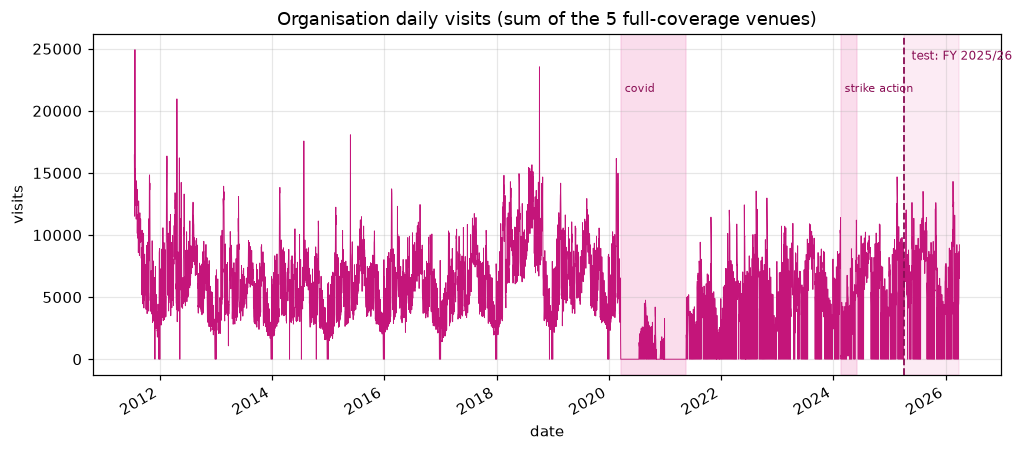

In [10]:
display(
    qdf(
        f"SELECT MIN(date) first_date, MAX(date) last_date, COUNT(*) n "
        f"FROM visits_daily WHERE date <= '{DATA_END.date()}'"
    )
)
display(
    qdf(
        f"SELECT MIN(`datetime`) first_date, MAX(`datetime`) last_date, COUNT(*) n "
        f"FROM visits_hourly WHERE `datetime` <= '{DATA_END.date()} 23:59:59'"
    )
)
display(
    qdf(
        f"SELECT area, MIN(date) first_date, MAX(date) last_date, COUNT(*) n "
        f"FROM weather_daily WHERE date <= '{DATA_END.date()}' GROUP BY area"
    )
)
display(
    qdf(
        f"SELECT area, MIN(start_dt) first_date, MAX(start_dt) last_date, COUNT(*) n "
        f"FROM weather_3hourly WHERE start_dt < '{(DATA_END + pd.Timedelta(days=1)).date()}' "
        "GROUP BY area"
    )
)
display(
    qdf(
        "SELECT MIN(date) first_date, MAX(date) last_date, COUNT(*) n, "
        + ", ".join(f"SUM({c} IS NULL OR TRIM({c}) = '') {c}_null_or_blank" for c in LA_COLS)
        + " FROM term_dates"
    )
)

audit = pd.DataFrame(
    {
        c: {
            "first": daily[c]["date"].min().date(),
            "last": daily[c]["date"].max().date(),
            "rows": len(daily[c]),
            "closed_or_zero": int((daily[c]["visits"].fillna(0) == 0).sum()),
        }
        for c in ACTIVE
    }
).T
display(audit)

ax = gdf_total.plot(
    x="date",
    y="visits",
    legend=False,
    lw=0.6,
    title=f"Organisation daily visits (sum of the {len(TOTAL_VENUES)} full-coverage venues)",
)
for _name, (_a, _b) in DISRUPTIONS.items():
    ax.axvspan(_a, _b, color=PINKS[3], alpha=0.35)
    ax.text(
        _a,
        ax.get_ylim()[1] * 0.85,
        " " + _name.replace("_", " "),
        color=PINKS[2],
        fontsize=7,
        va="top",
    )
ax.axvspan(TEST_START, TEST_END, color=PINKS[1], alpha=0.12)
ax.axvline(TEST_START, color=PINKS[2], ls="--", lw=1.2)
if TRAIN_START is not None:
    ax.axvline(TRAIN_START, color="#6E6772", ls=":", lw=1)
ax.text(
    TEST_START,
    ax.get_ylim()[1] * 0.95,
    f"  test: {window_label(TEST_START, TEST_END)}",
    color=PINKS[2],
    fontsize=8,
    va="top",
)
ax.set_ylabel("visits")
plt.tight_layout()

11. Compares the seven venues on Pearson, Spearman and mutual information. The primary venue is the highest-ranked venue still reporting at the end of the data.

,pearson,spearman,mutual_info,combined_rank
MoL,0.557,0.676,0.388,1.333
MM,0.574,0.653,0.367,1.667
ISM,0.550,0.625,0.304,3.000
WM,0.504,0.600,0.275,4.000
WAG,0.487,0.574,0.267,5.000
LLAG,0.421,0.527,0.210,6.000
SH,0.300,0.388,0.119,7.000


Most representative venue across all three measures: MoL


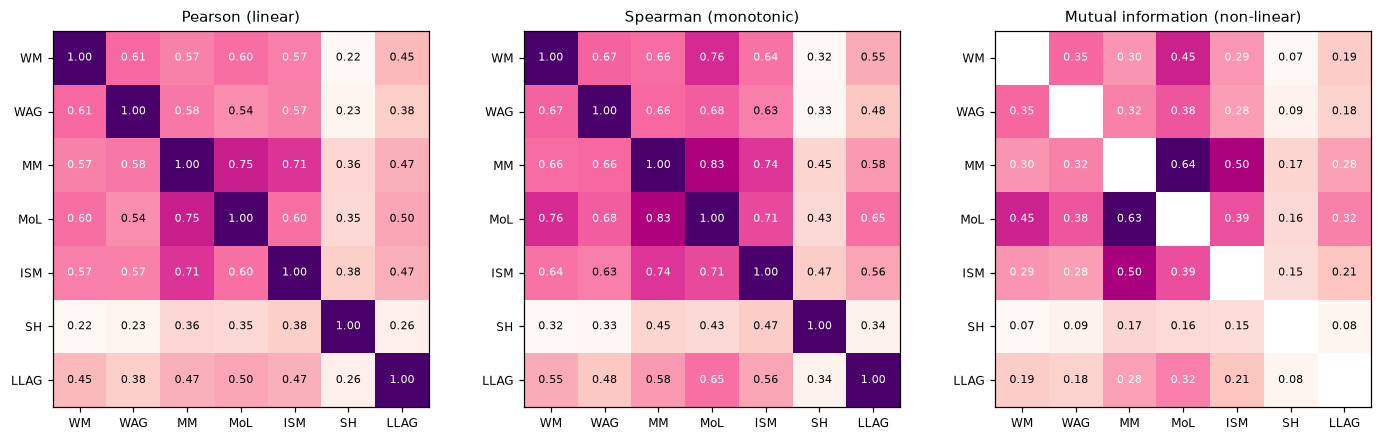

In [11]:
venue_visits = wide.set_index("date")[ACTIVE].astype(float)
venue_visits = venue_visits.where(venue_visits > 0)  # ignore closed days

pear, spear = venue_visits.corr("pearson"), venue_visits.corr("spearman")


def mi_matrix(venue_visits):
    cols = venue_visits.columns
    mat = pd.DataFrame(np.nan, index=cols, columns=cols)
    for a in cols:
        for b in cols:
            if a == b:
                continue
            xy = venue_visits[[a, b]].dropna()
            mat.loc[a, b] = mutual_info_regression(
                xy[[a]].values, xy[b].values, random_state=RANDOM_STATE
            )[0]
    return mat


mi = mi_matrix(venue_visits)


def heat(mat, title, ax, fmt="{:.2f}"):
    im = ax.imshow(mat.values.astype(float), cmap=CMAP)
    ax.set_xticks(range(len(mat.columns)))
    ax.set_xticklabels(mat.columns, fontsize=8)
    ax.set_yticks(range(len(mat.index)))
    ax.set_yticklabels(mat.index, fontsize=8)
    thr = np.nanmean(mat.values.astype(float))
    for i in range(len(mat.index)):
        for j in range(len(mat.columns)):
            v = mat.values[i, j]
            if not pd.isna(v):
                ax.text(
                    j,
                    i,
                    fmt.format(v),
                    ha="center",
                    va="center",
                    fontsize=7,
                    color="white" if v > thr else "black",
                )
    ax.set_title(title, fontsize=10)
    ax.grid(False)


fig, axes = plt.subplots(1, 3, figsize=(13, 4))
heat(pear, "Pearson (linear)", axes[0])
heat(spear, "Spearman (monotonic)", axes[1])
heat(mi, "Mutual information (non-linear)", axes[2])
plt.tight_layout()


def offdiag_mean(mat):
    arr = mat.to_numpy(dtype=float, copy=True)
    np.fill_diagonal(arr, np.nan)
    return pd.Series(np.nanmean(arr, axis=1), index=mat.index)


rank = pd.DataFrame(
    {
        "pearson": offdiag_mean(pear),
        "spearman": offdiag_mean(spear),
        "mutual_info": offdiag_mean(mi),
    }
)
rank["combined_rank"] = rank.rank(ascending=False).mean(axis=1)
rank = rank.sort_values("combined_rank")
display(rank.round(3))
# The primary venue needs test-window data, so it is the highest-ranked venue still reporting.
PRIMARY_VENUE = next(v for v in rank.index if v in TOTAL_VENUES)
print(f"Most representative venue across all three measures: {rank.index[0]}")
if PRIMARY_VENUE != rank.index[0]:
    print(
        f"{rank.index[0]} has stopped reporting, so the primary venue is the highest-ranked venue "
        f"still reporting: {PRIMARY_VENUE}"
    )

12. build_features(): calendar, school-holiday, disruption, Fourier, lag, rolling-mean and weather features for a direct h-step model, using only lags of at least the horizon. A row is kept only when every weather column is present, so designs that differ only in weather use identical rows.

In [12]:
DEFAULT_WX = (
    "oh_temp_c",
    "oh_feels_like_c",
    "oh_rain_1h_mm",
    "oh_snow_1h_mm",
    "oh_wind_speed_ms",
    "oh_clouds_pct",
    "temp_c",
    "feels_like_c",
    "rain_1h_mm",
    "clouds_pct",
    "visibility_m",
)  # daily weather base design
WX_ALL = DEFAULT_WX + WX_3H
DEFAULT_LAGS = (1, 2, 3, 7, 14, 21, 28, 364)


def build_features(
    frame,
    horizon=1,
    target="visits",
    weather_cols=DEFAULT_WX,
    lags=DEFAULT_LAGS,
    rolls=(7, 28),
    return_future=False,
):
    """Design matrix for a direct h-step-ahead model. Only lags greater than or equal to horizon are used and rolling means are shifted by horizon, so no future data leaks in."""
    df = frame.sort_values("date").copy()
    full = pd.DataFrame({"date": pd.date_range(df["date"].min(), df["date"].max(), freq="D")})
    df = full.merge(df, on="date", how="left")  # one row per day, so a row shift is a day shift
    d = df["date"]
    df["dow"], df["month"], df["doy"] = d.dt.dayofweek, d.dt.month, d.dt.dayofyear
    df["is_weekend"] = (df["dow"] >= 5).astype(int)
    df["bank_hol"] = bank_holiday_flag(d).values
    df["school_hol"] = school_holiday_flag(d).values
    df["school_hol_share"] = school_holiday_share(d).values
    for name, (start, end) in DISRUPTIONS.items():
        df[name] = ((d >= start) & (d <= end)).astype(int)
    for k in (1, 2, 3):
        df[f"sin{k}"] = np.sin(2 * np.pi * k * df["doy"] / 365.25)
        df[f"cos{k}"] = np.cos(2 * np.pi * k * df["doy"] / 365.25)
    y_num = pd.to_numeric(df[target], errors="coerce")
    y_open = y_num.where(lambda s: s > 0)  # open days only
    if CLOSED_IS_ZERO and y_num.notna().any():
        # Closures inside the observed span are known zeros; days before the series starts stay NaN.
        obs = d[y_num.notna()]
        inside = (d >= obs.min()) & (d <= obs.max())
        y_hist = y_num.mask(inside & y_num.isna(), 0.0)
    else:
        y_hist = y_open
    y_ff = y_open.ffill()  # last open day's visits, for the naive baselines
    for lag in lags:
        if lag >= horizon:
            df[f"lag_{lag}"] = y_hist.shift(lag)
            # lag_ counts a closure as zero; nlag_ carries the last open day, as a naive forecaster would.
            df[f"nlag_{lag}"] = y_ff.shift(lag)
    for w in rolls:
        df[f"roll_{w}"] = y_hist.shift(horizon).rolling(w, min_periods=max(3, w // 2)).mean()
    # Closed days in the last week, so a zero lag from a closure is not read as a fall in demand.
    df["closed_7"] = (y_hist <= 0).astype(float).shift(horizon).rolling(7, min_periods=1).sum()
    wx = [c for c in weather_cols if c in df.columns]
    x_cols = (
        ["month", "dow", "is_weekend", "bank_hol", "school_hol", "school_hol_share"]
        + ([] if DROP_DISRUPTED_DAYS else list(DISRUPTIONS))
        + ["closed_7", "sin1", "cos1", "sin2", "cos2", "sin3", "cos3"]
        + [c for c in df.columns if c.startswith(("lag_", "nlag_", "roll_"))]
        + wx
    )
    x_all = pd.get_dummies(df[x_cols], columns=["month", "dow"]).astype(float)
    # Every weather column must be present, used or not, so all weather designs share identical rows.
    wx_present = df[[c for c in WX_ALL if c in df.columns]].notna().all(axis=1)
    feat_ok = x_all.notna().all(axis=1) & wx_present
    known = feat_ok & (y_open > 0)
    if DROP_DISRUPTED_DAYS:
        known &= ~disrupted(d)
    out = (
        d[known].reset_index(drop=True),
        x_all[known].reset_index(drop=True),
        y_open[known].astype(float).reset_index(drop=True),
    )
    if not return_future:
        return out
    fut = feat_ok & df[target].isna()
    return out + (d[fut].reset_index(drop=True), x_all[fut].reset_index(drop=True))


def weather_variant(x, keep):
    """X with its non-weather columns plus only the weather columns in keep."""
    return x[[c for c in x.columns if c not in WX_ALL or c in keep]]


def feature_group(c):
    """Group label for a design-matrix column, used by Boruta, permutation importance and the ablation."""
    if c in WX_3H:
        return "3-hourly weather"
    if c in DEFAULT_WX:
        return "daily weather"
    if c.startswith(("lag_", "nlag_", "roll_")) or c == "closed_7":
        return "lags and rolling means"
    if c.startswith("school_hol"):
        return "school holidays"
    if c == "bank_hol":
        return "bank holidays"
    if c.startswith(("month_", "sin", "cos")):
        return "seasonal terms"
    return "day of week and other calendar"

13. Metrics, the chronological train/test split, TimeSeriesSplit cross-validation and the naive baselines, which use the last open day so that a closure does not produce a forecast of zero.

In [13]:
def metrics(y_true, y_pred):
    y, p = np.asarray(y_true, float), np.asarray(y_pred, float)
    rmse = float(np.sqrt(np.mean((y - p) ** 2)))
    pos = y > 0
    return {
        "RMSE": rmse,
        "nRMSE_%": 100 * rmse / y.mean() if y.mean() > 0 else np.nan,
        "MAE": float(np.mean(np.abs(y - p))),
        "MAPE_%": (
            float(100 * np.mean(np.abs((y[pos] - p[pos]) / y[pos]))) if pos.any() else np.nan
        ),
        "R2": float(1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2)),
    }


def chrono_split(dates, x, y, train=None, test=None):
    """Rows inside the training and test windows from the tuning cell, or the (start, end) pairs given."""
    train = train or (TRAIN_START, TRAIN_END)
    test = test or (TEST_START, TEST_END)
    tr, te = in_window(dates, *train), in_window(dates, *test)
    return x.loc[tr], x.loc[te], y.loc[tr], y.loc[te], dates.loc[tr], dates.loc[te]


def cv_scores(model_fn, x, y, n_splits=5):
    rows = []
    for i, (tr, te) in enumerate(TimeSeriesSplit(n_splits=n_splits).split(x)):
        m = model_fn()
        m.fit(x.iloc[tr], y.iloc[tr])
        rows.append({**metrics(y.iloc[te], m.predict(x.iloc[te])), "fold": i})
    return pd.DataFrame(rows)


def naive_pred(x, horizon):
    """Last open day's visits (nlag_), so a closure does not give a forecast of zero."""
    cols = sorted(
        (c for c in x.columns if c.startswith("nlag_")), key=lambda s: int(s.split("_")[1])
    )
    col = f"nlag_{horizon}" if f"nlag_{horizon}" in x.columns else cols[0]
    return x[col].values


def snaive_pred(x, horizon):
    """Same weekday, the smallest whole number of weeks back that is at least the horizon."""
    lag = 7 * int(np.ceil(horizon / 7))
    return x[f"nlag_{lag}"].values if f"nlag_{lag}" in x.columns else naive_pred(x, horizon)


def cv_baseline(pred_fn, x, y, horizon, n_splits=5):
    rows = []
    for i, (tr, te) in enumerate(TimeSeriesSplit(n_splits=n_splits).split(x)):
        rows.append({**metrics(y.iloc[te], pred_fn(x.iloc[te], horizon)), "fold": i})
    return pd.DataFrame(rows)

14. Builds the one-day-ahead design for the organisation total, scores the naive baselines on the test window, then fits SARIMA on the training window and steps it through the test window one day at a time.

In [14]:
dates1, x1, y1 = build_features(gdf_total, horizon=1)
_dates1a, x1_all, _ = build_features(gdf_total, horizon=1, weather_cols=WX_ALL)
assert dates1.equals(_dates1a), "daily and 3-hourly designs must share rows"

x1_tr, x1_te, y1_tr, y1_te, d1_tr, d1_te = chrono_split(dates1, x1, y1)
x1a_tr, x1a_te = (
    x1_all.loc[x1_tr.index],
    x1_all.loc[x1_te.index],
)  # same rows, 3-hourly weather added
print(
    f"train {d1_tr.min().date()} -> {d1_tr.max().date()} ({len(y1_tr)} open days) | "
    f"test {d1_te.min().date()} -> {d1_te.max().date()} ({len(y1_te)} open days)"
)
print(
    f"the test window has {len(y1_te)} usable days out of "
    f"{len(pd.date_range(TEST_START, TEST_END, freq='D'))} calendar days"
)

# How much of the data reaches the models.
_span = pd.date_range(gdf_total["date"].min(), DATA_END, freq="D")
_open = pd.to_numeric(gdf_total["visits"], errors="coerce") > 0
print(
    f"organisation series {gdf_total['date'].min().date()} -> {DATA_END.date()}: "
    f"{len(_span)} calendar "
    "days, "
    f"{int(_open.sum())} open, {len(y1)} usable after features ({len(y1) / int(_open.sum()):.0%} "
    "of open days)"
)
for _name, (_a, _b) in DISRUPTIONS.items():
    print(
        f"{_name.replace('_', ' ')} ({_a:%d %b %Y} to {_b:%d %b %Y}): "
        f"{int((_open & in_window(gdf_total['date'], _a, _b)).sum())} open days, "
        + (
            "dropped from training"
            if DROP_DISRUPTED_DAYS
            else "kept in training with a 0/1 feature"
        )
    )

results_h1 = {
    "Naive (t-1)": metrics(y1_te, naive_pred(x1_te, 1)),
    "SeasonalNaive (t-7)": metrics(y1_te, snaive_pred(x1_te, 1)),
}

# SARIMA is fitted on up to eight years ending with the training window, then stepped forward without refitting. Only test-window days are scored.
y_sar = gdf_total.set_index("date")["visits"].asfreq("D")
y_sar = y_sar.where(y_sar > 0)  # closures become missing
fit_from = TRAIN_END + pd.Timedelta(days=1) - pd.DateOffset(years=8)
if TRAIN_START is not None:
    fit_from = max(fit_from, TRAIN_START)
tr_s = y_sar[(y_sar.index >= fit_from) & (y_sar.index <= TRAIN_END)]
post = y_sar[(y_sar.index > TRAIN_END) & (y_sar.index <= TEST_END)]
res = SARIMAX(
    tr_s,
    order=(1, 0, 1),
    seasonal_order=(1, 1, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False,
).fit(disp=False)
pred = (
    res.append(post, refit=False)
    .get_prediction(start=post.index[0], end=post.index[-1])
    .predicted_mean
)
mask = (post.index >= TEST_START) & post.notna().to_numpy()
results_h1["SARIMA(1,0,1)(1,1,1)7"] = metrics(post[mask], pred[mask])
pd.DataFrame(results_h1).T.round(2)

train 2012-07-17 -> 2025-03-30 (3868 open days) | test 2025-04-01 -> 2026-03-31 (322 open days)
the test window has 322 usable days out of 365 calendar days
organisation series 2011-07-19 -> 2026-03-31: 5370 calendar days, 4783 open, 4190 usable after features (88% of open days)
covid (18 Mar 2020 to 17 May 2021): 100 open days, dropped from training
strike action (17 Feb 2024 to 04 Jun 2024): 98 open days, dropped from training


,RMSE,nRMSE_%,MAE,MAPE_%,R2
Naive (t-1),2084.55,31.52,1515.89,23.16,0.34
SeasonalNaive (t-7),2484.54,37.56,1587.91,25.89,0.07
"SARIMA(1,0,1)(1,1,1)7",1351.90,20.48,977.47,15.85,0.72


15. LSTMRegressor: an LSTM behind the scikit-learn fit/predict interface, so it runs through the same code as Ridge, Random Forest and XGBoost.

In [15]:
SEQ_LEN = 14  # open days of history in each sequence


class _LSTMNet(nn.Module):
    """LSTM stack with a linear head reading the final hidden state."""

    def __init__(self, n_features, hidden, layers, dropout):
        super().__init__()
        self.lstm = nn.LSTM(
            n_features,
            hidden,
            num_layers=layers,
            batch_first=True,
            dropout=dropout if layers > 1 else 0.0,
        )
        self.head = nn.Linear(hidden, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1, :]).squeeze(-1)


def _sequences(arr, seq_len):
    """(n, f) -> (n - seq_len + 1, seq_len, f). One window per row, ending on that row."""
    idx = np.arange(seq_len)[None, :] + np.arange(len(arr) - seq_len + 1)[:, None]
    return arr[idx]


class LSTMRegressor(RegressorMixin, BaseEstimator):
    """LSTM with the scikit-learn fit/predict interface, so it runs through the same code as the
    other models.

    Each example is the previous `seq_len` rows of the design matrix, and the target is the value
    on the last row. Rows are open days, so closures are skipped, as in the other models.

    predict() assumes X follows on from the rows fit() last saw, which holds for the test window
    and TimeSeriesSplit. It prepends the last seq_len - 1 training rows so the first test row has a
    full window, using past predictors only. Inputs and target are scaled on training rows alone.
    """

    def __init__(
        self,
        seq_len=SEQ_LEN,
        hidden=64,
        layers=1,
        dropout=0.0,
        epochs=150,
        batch_size=32,
        lr=1e-3,
        weight_decay=1e-4,
        patience=15,
        val_frac=0.15,
        random_state=RANDOM_STATE,
        verbose=False,
    ):
        self.seq_len = seq_len
        self.hidden = hidden
        self.layers = layers
        self.dropout = dropout
        self.epochs = epochs
        self.batch_size = batch_size
        self.lr = lr
        self.weight_decay = weight_decay
        self.patience = patience
        self.val_frac = val_frac
        self.random_state = random_state
        self.verbose = verbose

    def fit(self, x, y):
        torch.manual_seed(self.random_state)
        np.random.seed(self.random_state)

        xa = np.asarray(x, dtype=np.float64)
        ya = np.asarray(y, dtype=np.float64)
        if len(xa) <= self.seq_len:
            raise ValueError(f"need more than {self.seq_len} rows to build a sequence")

        self.x_scaler_ = StandardScaler().fit(xa)
        self.y_mean_ = float(ya.mean())
        self.y_std_ = float(ya.std()) or 1.0
        xs = self.x_scaler_.transform(xa).astype(np.float32)
        ys = ((ya - self.y_mean_) / self.y_std_).astype(np.float32)

        seqs = _sequences(xs, self.seq_len)  # (m, seq_len, f)
        t = ys[self.seq_len - 1 :]  # target on each window's last row
        n_val = max(1, int(len(seqs) * self.val_frac))  # chronological tail, for early stopping
        n_tr = len(seqs) - n_val

        xtr, ytr = torch.from_numpy(seqs[:n_tr]), torch.from_numpy(t[:n_tr])
        xva, yva = torch.from_numpy(seqs[n_tr:]), torch.from_numpy(t[n_tr:])

        self.net_ = _LSTMNet(xs.shape[1], self.hidden, self.layers, self.dropout)
        opt = torch.optim.Adam(self.net_.parameters(), lr=self.lr, weight_decay=self.weight_decay)
        lossf = nn.MSELoss()
        loader = DataLoader(TensorDataset(xtr, ytr), batch_size=self.batch_size, shuffle=True)

        best, best_state, bad, ep = np.inf, None, 0, 0
        for ep in range(self.epochs):
            self.net_.train()
            for xb, yb in loader:
                opt.zero_grad()
                lossf(self.net_(xb), yb).backward()
                nn.utils.clip_grad_norm_(self.net_.parameters(), 1.0)
                opt.step()
            self.net_.eval()
            with torch.no_grad():
                vloss = float(lossf(self.net_(xva), yva))
            if vloss < best - 1e-5:
                best, best_state, bad = vloss, copy.deepcopy(self.net_.state_dict()), 0
            else:
                bad += 1
                if bad >= self.patience:
                    break
            if self.verbose and ep % 10 == 0:
                print(f"  epoch {ep:3d}  val MSE {vloss:.4f}")

        if best_state is not None:
            self.net_.load_state_dict(best_state)
        self.tail_ = (
            xs[-(self.seq_len - 1) :]
            if self.seq_len > 1
            else np.empty((0, xs.shape[1]), np.float32)
        )
        self.n_features_in_ = xs.shape[1]
        self.best_val_loss_, self.epochs_run_ = best, ep + 1
        return self

    def predict(self, x):
        xs = self.x_scaler_.transform(np.asarray(x, dtype=np.float64)).astype(np.float32)
        seqs = torch.from_numpy(_sequences(np.vstack([self.tail_, xs]), self.seq_len))
        self.net_.eval()
        with torch.no_grad():
            out = self.net_(seqs).numpy()
        return out * self.y_std_ + self.y_mean_


_probe = LSTMRegressor(epochs=2).fit(x1_tr, y1_tr)
print(
    f"wrapper OK: {x1_tr.shape[1]} features -> sequences of {SEQ_LEN} rows, "
    f"{len(_probe.predict(x1_te))} test predictions for {len(y1_te)} test days"
)

wrapper OK: 59 features -> sequences of 14 rows, 322 test predictions for 322 test days


16. Benchmarks Ridge, Random Forest, XGBoost and the LSTM against seasonal-naive with the same TimeSeriesSplit cross-validation on the training window.

In [16]:
def make_models():
    return {
        "Ridge": lambda: Pipeline([("sc", StandardScaler()), ("m", Ridge(alpha=1.0))]),
        "RandomForest": lambda: RandomForestRegressor(
            n_estimators=500, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE
        ),
        "XGBoost": lambda: XGBRegressor(
            n_estimators=800,
            learning_rate=0.05,
            max_depth=6,
            subsample=0.9,
            colsample_bytree=0.9,
            tree_method="hist",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
        "LSTM": lambda: LSTMRegressor(),
    }


# 5-fold TimeSeriesSplit on the training window only.
cv_tables = {name: cv_scores(fn, x1_tr, y1_tr) for name, fn in make_models().items()}
cv_tables["SeasonalNaive"] = cv_baseline(snaive_pred, x1_tr, y1_tr, 1)
cv_summary = (
    pd.concat([t.assign(model=n) for n, t in cv_tables.items()])
    .groupby("model")[["nRMSE_%", "RMSE", "MAE", "MAPE_%"]]
    .agg(["mean", "std"])
    .round(2)
    .sort_values(("nRMSE_%", "mean"))
)
display(cv_summary)

nRMSE_%           RMSE              MAE         MAPE_%      
                 mean   std     mean     std     mean     std   mean   std
model                                                                     
XGBoost         20.63  4.81  1225.58  481.81   845.87  348.89  14.48  2.39
RandomForest    21.09  4.13  1246.05  424.10   846.78  305.48  14.46  1.81
LSTM            21.48  4.76  1268.54  454.96   889.77  321.51  16.12  3.26
Ridge           22.37  2.86  1306.16  292.00   929.81  217.09  16.74  1.72
SeasonalNaive   41.57  8.02  2377.81  267.77  1509.52  140.67  28.33  3.24

17. Prophet with weather and holiday regressors, fitted on the training window and scored on the test window.

In [17]:
pf = gdf_total.loc[
    pd.to_numeric(gdf_total["visits"], errors="coerce").fillna(0) > 0,
    ["date", "visits", "oh_temp_c", "oh_rain_1h_mm"],
].copy()
pf.columns = ["ds", "y", "oh_temp_c", "oh_rain_1h_mm"]
pf["school_hol"] = school_holiday_flag(pf["ds"]).values
pf["bank_hol"] = bank_holiday_flag(pf["ds"]).values
pf = pf.dropna()
tr_p = pf[in_window(pf["ds"], TRAIN_START, TRAIN_END)]
te_p = pf[in_window(pf["ds"], TEST_START, TEST_END)]
if DROP_DISRUPTED_DAYS:
    tr_p = tr_p[~disrupted(tr_p["ds"])]

mp = Prophet(weekly_seasonality=True, yearly_seasonality=True, daily_seasonality=False)
for r in ["oh_temp_c", "oh_rain_1h_mm", "school_hol", "bank_hol"]:
    mp.add_regressor(r)
mp.fit(tr_p)

fc = mp.predict(te_p.drop(columns="y"))
results_h1["Prophet (+regressors)"] = metrics(te_p["y"].values, fc["yhat"].values)
print(pd.Series(results_h1["Prophet (+regressors)"]).round(2))

14:30:05 - cmdstanpy - INFO - Chain [1] start processing
14:30:05 - cmdstanpy - INFO - Chain [1] done processing


RMSE       1457.98
nRMSE_%      22.08
MAE        1156.90
MAPE_%       19.74
R2            0.68
dtype: float64


18. Scores the LSTM on the test window, then compares sequence lengths on the training window. Refits the network for each length and fold.

In [18]:
# Test window score, with the same design and split as every other model.
lstm = LSTMRegressor()
lstm.fit(x1_tr, y1_tr)
LSTM_NAME = f"LSTM (seq={lstm.seq_len}, hidden={lstm.hidden})"
results_h1[LSTM_NAME] = metrics(y1_te, lstm.predict(x1_te))
print(
    f"{LSTM_NAME}: early stopping after {lstm.epochs_run_} epochs "
    f"(best scaled validation MSE {lstm.best_val_loss_:.4f})"
)

# Sequence-length check on the training window, with 3 folds to save time.
sens = []
for sl in (7, 14, 28):
    t = cv_scores(lambda sl=sl: LSTMRegressor(seq_len=sl), x1_tr, y1_tr, n_splits=3)
    sens.append({"seq_len": sl, "cv_nRMSE_%": t["nRMSE_%"].mean(), "cv_std": t["nRMSE_%"].std()})
display(pd.DataFrame(sens).round(2).sort_values("cv_nRMSE_%"))

LSTM (seq=14, hidden=64): early stopping after 18 epochs (best scaled validation MSE 0.0909)


,seq_len,cv_nRMSE_%,cv_std
1,14,21.16,4.93
0,7,21.40,4.32
2,28,22.46,5.81


19. Compares every model family on the test window and plots the LSTM against actual visits.

,RMSE,nRMSE_%,MAE,MAPE_%,R2
"LSTM (seq=14, hidden=64)",883.56,13.36,677.46,10.94,0.88
"SARIMA(1,0,1)(1,1,1)7",1351.90,20.48,977.47,15.85,0.72
Prophet (+regressors),1457.98,22.08,1156.90,19.74,0.68
Naive (t-1),2084.55,31.52,1515.89,23.16,0.34
SeasonalNaive (t-7),2484.54,37.56,1587.91,25.89,0.07


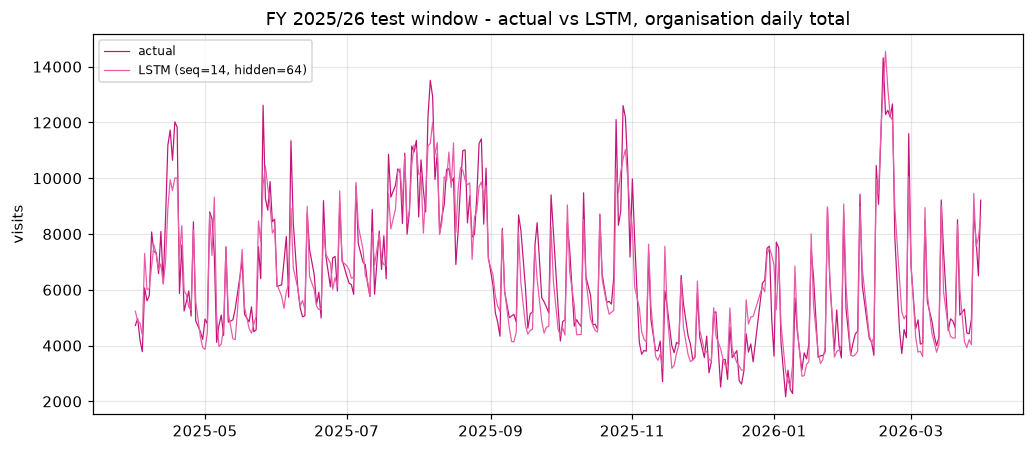

In [19]:
# Prophet and SARIMA keep every open day, while the lag-based models need a complete feature row, so the row sets differ slightly.
display(pd.DataFrame(results_h1).T.round(2).sort_values("nRMSE_%"))

fig, ax = plt.subplots(figsize=(9.5, 4.2))
ax.plot(d1_te, y1_te.values, lw=0.8, label="actual")
ax.plot(d1_te, lstm.predict(x1_te), lw=0.8, label=LSTM_NAME)
ax.set_title(
    f"{window_label(TEST_START, TEST_END)} test window - actual vs LSTM, organisation daily total"
)
ax.set_ylabel("visits")
ax.legend(fontsize=8)
plt.tight_layout()

20. Tunes XGBoost with RandomizedSearchCV over TimeSeriesSplit on the training window, and defines make_best() for every later test.

In [20]:
space = {
    "n_estimators": [300, 500, 800],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth": [4, 6, 8],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.7, 1.0],
    "min_child_weight": [1, 5],
}
rs = RandomizedSearchCV(
    XGBRegressor(tree_method="hist", random_state=RANDOM_STATE, n_jobs=-1),
    space,
    n_iter=25,
    cv=TimeSeriesSplit(n_splits=4),
    scoring="neg_root_mean_squared_error",
    random_state=RANDOM_STATE,
    n_jobs=1,
)
rs.fit(x1_tr, y1_tr)

BEST_PARAMS, BEST_NAME = rs.best_params_, "XGBoost (tuned)"


def make_best():
    return XGBRegressor(tree_method="hist", random_state=RANDOM_STATE, n_jobs=-1, **BEST_PARAMS)


print(BEST_NAME, BEST_PARAMS, f"| CV RMSE = {-rs.best_score_:.1f}")

XGBoost (tuned) {'subsample': 0.8, 'n_estimators': 300, 'min_child_weight': 5, 'max_depth': 6, 'learning_rate': 0.03, 'colsample_bytree': 0.7} | CV RMSE = 1213.7


21. Refits the LSTM and the tuned XGBoost with five random seeds on the same split, to check whether the gap between them is larger than the variation between seeds.

In [21]:
# One seed cannot separate a better model from a lucky initialisation. Both models are random (XGBoost through subsampling), so both are refitted with each seed on the same h = 1 split.
SEEDS = [RANDOM_STATE + i for i in range(5)]

seed_rows = []
for s in SEEDS:
    for name, fn in {
        "LSTM": lambda s=s: LSTMRegressor(random_state=s),
        BEST_NAME: lambda s=s: XGBRegressor(
            tree_method="hist", n_jobs=-1, random_state=s, **BEST_PARAMS
        ),
    }.items():
        m = fn()
        m.fit(x1_tr, y1_tr)
        seed_rows.append({"model": name, "seed": s, **metrics(y1_te, m.predict(x1_te))})

seeds_df = pd.DataFrame(seed_rows)
seed_summary = (
    seeds_df.groupby("model")["nRMSE_%"].agg(mean="mean", std="std", min="min", max="max").round(2)
)
seed_summary["seeds_meeting_threshold"] = (
    seeds_df.assign(ok=seeds_df["nRMSE_%"] <= ACCEPT_NRMSE)
    .groupby("model")["ok"]
    .sum()
    .astype(int)
    .astype(str)
    + f" / {len(SEEDS)}"
)
display(seed_summary)
display(seeds_df.pivot(index="seed", columns="model", values="nRMSE_%").round(2))

_gap = seed_summary.loc["LSTM", "mean"] - seed_summary.loc[BEST_NAME, "mean"]
_spread = seed_summary["std"].max()
print(
    f"Mean test-window gap, LSTM minus {BEST_NAME}: {_gap:+.2f} points of nRMSE "
    f"(largest seed-to-seed std: {_spread:.2f})."
)
print(
    f"The gap is {'larger' if abs(_gap) > _spread else 'no larger'} than the seed-to-seed spread, "
    "so the "
    "ranking "
    f"{'holds across seeds' if abs(_gap) > _spread else 'is not robust to initialisation'}."
)

,mean,std,min,max,seeds_meeting_threshold
model,,,,,
LSTM,13.42,0.21,13.22,13.75,5 / 5
XGBoost (tuned),13.26,0.12,13.17,13.46,5 / 5


model,LSTM,XGBoost (tuned)
seed,,
42,13.36,13.20
43,13.22,13.17
44,13.75,13.29
45,13.27,13.20
46,13.49,13.46


Mean test-window gap, LSTM minus XGBoost (tuned): +0.16 points of nRMSE (largest seed-to-seed std: 0.21).
The gap is no larger than the seed-to-seed spread, so the ranking is not robust to initialisation.


22. Boruta against shuffled shadow features, on the design with daily and 3-hourly weather, with the number of features it confirms in each group.

In [22]:
for _a, _t in (
    ("int", int),
    ("float", float),
    ("bool", bool),
):  # BorutaPy needs the old numpy aliases
    if not hasattr(np, _a):
        setattr(np, _a, _t)

rf_b = RandomForestRegressor(n_estimators=250, max_depth=7, n_jobs=-1, random_state=RANDOM_STATE)
bor = BorutaPy(rf_b, n_estimators="auto", max_iter=60, random_state=RANDOM_STATE, verbose=0)
bor.fit(x1a_tr.values, y1_tr.values)

confirmed = list(x1a_tr.columns[bor.support_])
tentative = list(x1a_tr.columns[bor.support_weak_])
SELECTED = (confirmed + tentative) if confirmed else list(x1a_tr.columns)
print(f"Boruta confirmed ({len(confirmed)}): {confirmed}")
print(f"Boruta tentative ({len(tentative)}): {tentative}")

bor_groups = (
    pd.DataFrame(
        {
            "group": [feature_group(c) for c in x1a_tr.columns],
            "confirmed": bor.support_,
            "tentative": bor.support_weak_,
        }
    )
    .groupby("group")
    .agg(
        features=("group", "size"), confirmed=("confirmed", "sum"), tentative=("tentative", "sum")
    )
)
display(bor_groups)

Boruta confirmed (19): ['school_hol', 'school_hol_share', 'sin1', 'cos1', 'sin2', 'sin3', 'lag_1', 'nlag_1', 'nlag_3', 'lag_7', 'nlag_7', 'lag_14', 'nlag_14', 'lag_364', 'nlag_364', 'roll_7', 'roll_28', 'dow_5', 'dow_6']
Boruta tentative (4): ['is_weekend', 'cos3', 'nlag_21', 'nlag_28']


,features,confirmed,tentative
group,,,
3-hourly weather,56,0,0
bank holidays,1,0,0
daily weather,11,0,0
day of week and other calendar,8,2,1
lags and rolling means,19,11,2
school holidays,2,2,0
seasonal terms,18,4,1


23. Permutation importance on a validation slice at the end of the training window, with the share carried by daily and by 3-hourly weather.

Share of positive permutation importance: daily weather 0.1%, 3-hourly weather 1.2% (bars: darkest = 3-hourly, mid = daily weather)


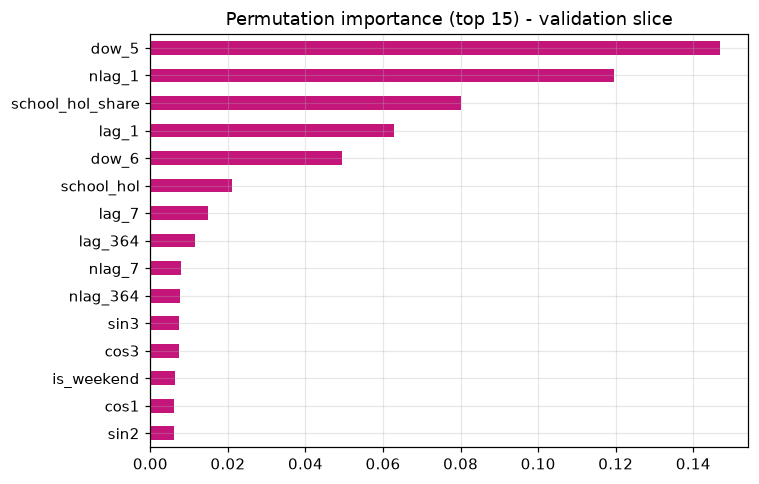

In [23]:
k = int(len(x1a_tr) * 0.8)  # validation slice inside the training window
mb = make_best()
mb.fit(x1a_tr.iloc[:k], y1_tr.iloc[:k])
pi = permutation_importance(
    mb, x1a_tr.iloc[k:], y1_tr.iloc[k:], n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1
)
imp_all = pd.Series(pi.importances_mean, index=x1a_tr.columns)
imp = imp_all.sort_values().tail(15)
imp.plot.barh(
    title="Permutation importance (top 15) - validation slice",
    figsize=(7, 4.5),
    color=[
        PINKS[2] if c in WX_3H else PINKS[1] if c in DEFAULT_WX else PINKS[0] for c in imp.index
    ],
)
plt.tight_layout()

# Correlated columns split importance between them (daily and 3-hourly temperature, for example). See ablation in section 25 for test.
_pos = imp_all.clip(lower=0)
WX_SHARE = {
    g: 100 * _pos[[c for c in _pos.index if feature_group(c) == g]].sum() / _pos.sum()
    for g in ("daily weather", "3-hourly weather")
}
print(
    f"Share of positive permutation importance: daily weather {WX_SHARE['daily weather']:.1f}%, "
    f"3-hourly weather {WX_SHARE['3-hourly weather']:.1f}% (bars: darkest = 3-hourly, mid = daily "
    "weather)"
)

24. Cross-validated error for the daily-weather design, the design with 3-hourly weather added, and the Boruta-selected columns.

In [24]:
comp = pd.DataFrame(
    {
        "daily weather (base)": cv_scores(make_best, x1_tr, y1_tr)["nRMSE_%"].agg(["mean", "std"]),
        "daily + 3-hourly weather": cv_scores(make_best, x1a_tr, y1_tr)["nRMSE_%"].agg(
            ["mean", "std"]
        ),
        "boruta_selected": cv_scores(make_best, x1a_tr[SELECTED], y1_tr)["nRMSE_%"].agg(
            ["mean", "std"]
        ),
    }
).round(2)
display(comp)

,daily weather (base),daily + 3-hourly weather,boruta_selected
mean,20.32,20.69,20.82
std,4.46,4.30,4.03


25. Ablation: refits the tuned model on identical rows for each variant (no weather, 3-hourly instead of daily weather, both together, no school holidays, no seasonal terms), for the organisation total and the primary venue at each horizon in ABL_HORIZONS, scored by cross-validation and on the test window.

In [25]:
# Each design is built once with every weather column and each variant only drops column groups, so all variants use the same rows, split and hyperparameters. The base is the daily-weather design.
# delta = variant - base: positive means the variant did worse, so a removed group was helping. Weather is the observed weather on the day, so this is an upper bound for a live forecast.
ABL_HORIZONS = (1, 7, 28)
ABL_BASE = "daily weather (base)"
ABL_VARIANTS = {
    ABL_BASE: ("3-hourly weather",),
    "no weather": ("daily weather", "3-hourly weather"),
    "3-hourly instead of daily": ("daily weather",),
    "daily + 3-hourly": (),
    "no school holidays": ("3-hourly weather", "school holidays"),
    "no seasonal terms": ("3-hourly weather", "seasonal terms"),
}
WX_VARIANTS = ("no weather", "3-hourly instead of daily", "daily + 3-hourly")

_pv_cols = ["date", "visits"] + [c for c in WX_ALL if c in daily[PRIMARY_VENUE].columns]
ABL_SERIES = {"ALL (total)": gdf_total, PRIMARY_VENUE: daily[PRIMARY_VENUE][_pv_cols]}

abl_rows = []
for label, frame in ABL_SERIES.items():
    for h in ABL_HORIZONS:
        dts, x, y = build_features(frame, horizon=h, weather_cols=WX_ALL)
        xtr, xte, ytr, yte, _, _ = chrono_split(dts, x, y)
        grp = pd.Series([feature_group(c) for c in x.columns], index=x.columns)
        for name, drop in ABL_VARIANTS.items():
            cols = list(grp.index[~grp.isin(drop)])
            m = make_best()
            m.fit(xtr[cols], ytr)
            abl_rows.append(
                {
                    "series": label,
                    "horizon": h,
                    "variant": name,
                    "features": len(cols),
                    "cv_nRMSE_%": cv_scores(make_best, xtr[cols], ytr)["nRMSE_%"].mean(),
                    "test_nRMSE_%": metrics(yte, m.predict(xte[cols]))["nRMSE_%"],
                }
            )

abl = pd.DataFrame(abl_rows)
_base = (
    abl[abl["variant"] == ABL_BASE]
    .set_index(["series", "horizon"])[["cv_nRMSE_%", "test_nRMSE_%"]]
    .add_prefix("base_")
)
abl = abl.join(_base, on=["series", "horizon"])
abl["cv_delta"] = abl["cv_nRMSE_%"] - abl["base_cv_nRMSE_%"]
abl["test_delta"] = abl["test_nRMSE_%"] - abl["base_test_nRMSE_%"]
print(
    f"{len(abl)} fits scored: {len(ABL_SERIES)} series x {len(ABL_HORIZONS)} horizons x "
    f"{len(ABL_VARIANTS)} variants"
)

36 fits scored: 2 series x 3 horizons x 6 variants


26. Shows ablation tables and maps each variant's change in error against the daily-weather base, with permutation importance from section 23 as a cross-check.

Test-window nRMSE (%) by variant:


variant              daily weather (base)  no weather  \
series      horizon                                     
ALL (total) 1                       13.20       13.84   
            7                       15.26       15.68   
            28                      16.75       17.22   
MoL         1                       19.72       19.66   
            7                       21.18       20.93   
            28                      20.53       20.67   

variant              3-hourly instead of daily  daily + 3-hourly  \
series      horizon                                                
ALL (total) 1                            13.58             13.65   
            7                            15.19             15.49   
            28                           16.84             16.57   
MoL         1                            20.40             20.04   
            7                            21.25             21.61   
            28                           21.20             21.27   

variant              no school holidays  no seasonal terms  
series      horizon                                         
ALL (total) 1                     14.21              14.74  
            7                     18.53              17.72  
            28                    19.61              18.97  
MoL         1                     20.78              21.27  
            7                     23.84              23.50  
            28                    23.35              22.53

Cross-validated nRMSE (%) by variant:


variant              daily weather (base)  no weather  \
series      horizon                                     
ALL (total) 1                       20.32       20.58   
            7                       23.82       24.04   
            28                      24.98       25.07   
MoL         1                       24.81       24.68   
            7                       28.03       28.24   
            28                      28.97       28.65   

variant              3-hourly instead of daily  daily + 3-hourly  \
series      horizon                                                
ALL (total) 1                            20.55             20.69   
            7                            24.43             24.61   
            28                           25.37             25.49   
MoL         1                            24.74             25.06   
            7                            28.09             28.24   
            28                           29.40             29.36   

variant              no school holidays  no seasonal terms  
series      horizon                                         
ALL (total) 1                     21.47              21.03  
            7                     27.36              25.71  
            28                    28.68              28.40  
MoL         1                     26.13              25.44  
            7                     31.15              30.40  
            28                    32.13              32.19

Largest test-window change from any weather variant: +0.73 points of nRMSE (MoL, h=28, daily + 3-hourly).
Cross-check from section 23 (h = 1): daily weather carries 0.1% and 3-hourly weather 1.2% of positive permutation importance.


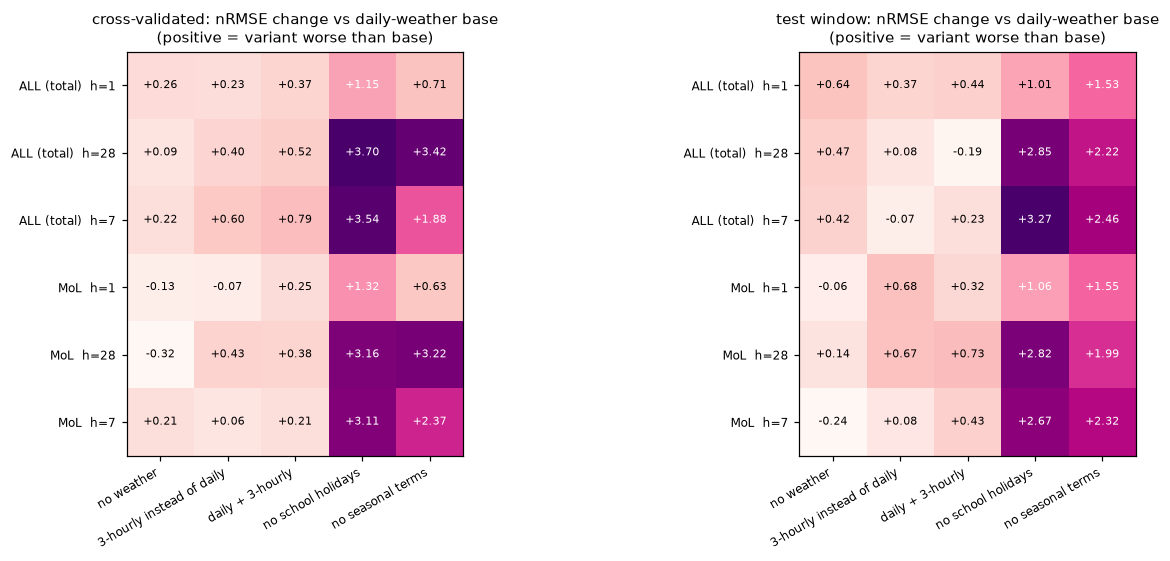

In [26]:
_order = list(ABL_VARIANTS)
print("Test-window nRMSE (%) by variant:")
display(
    abl.pivot_table(index=["series", "horizon"], columns="variant", values="test_nRMSE_%")[
        _order
    ].round(2)
)
print("Cross-validated nRMSE (%) by variant:")
display(
    abl.pivot_table(index=["series", "horizon"], columns="variant", values="cv_nRMSE_%")[
        _order
    ].round(2)
)

_d = abl[abl["variant"] != ABL_BASE].assign(
    row=lambda t: t["series"] + "  h=" + t["horizon"].astype(str)
)
fig, axes = plt.subplots(1, 2, figsize=(13, 0.9 + 0.45 * _d["row"].nunique() + 1.6))
for ax, col, what in (
    (axes[0], "cv_delta", "cross-validated"),
    (axes[1], "test_delta", "test window"),
):
    mat = _d.pivot(index="row", columns="variant", values=col)[
        [v for v in _order if v != ABL_BASE]
    ]
    heat(
        mat,
        f"{what}: nRMSE change vs daily-weather base\n(positive = variant worse than base)",
        ax,
        fmt="{:+.2f}",
    )
    plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
plt.tight_layout()

_wx = abl[abl["variant"].isin(WX_VARIANTS)]
_big = _wx.loc[_wx["test_delta"].abs().idxmax()]
print(
    f"Largest test-window change from any weather variant: {_big['test_delta']:+.2f} points of "
    "nRMSE "
    f"({_big['series']}, h={_big['horizon']}, {_big['variant']})."
)
print(
    f"Cross-check from section 23 (h = 1): daily weather carries {WX_SHARE['daily weather']:.1f}% "
    "and "
    f"3-hourly weather {WX_SHARE['3-hourly weather']:.1f}% of positive permutation importance."
)

27. Trains a separate direct model for each horizon in HORIZONS to show how accuracy falls further ahead.

horizon,1,7,14,28
model,,,,
XGBoost,13.16,15.39,15.14,16.97
XGBoost (tuned),13.20,15.26,15.30,16.75
LSTM,13.36,16.83,16.92,16.88
RandomForest,14.79,16.31,17.47,18.26
Ridge,16.92,20.07,20.20,20.54
Naive,31.52,37.56,42.49,45.62
SeasonalNaive,37.56,37.56,42.49,45.62


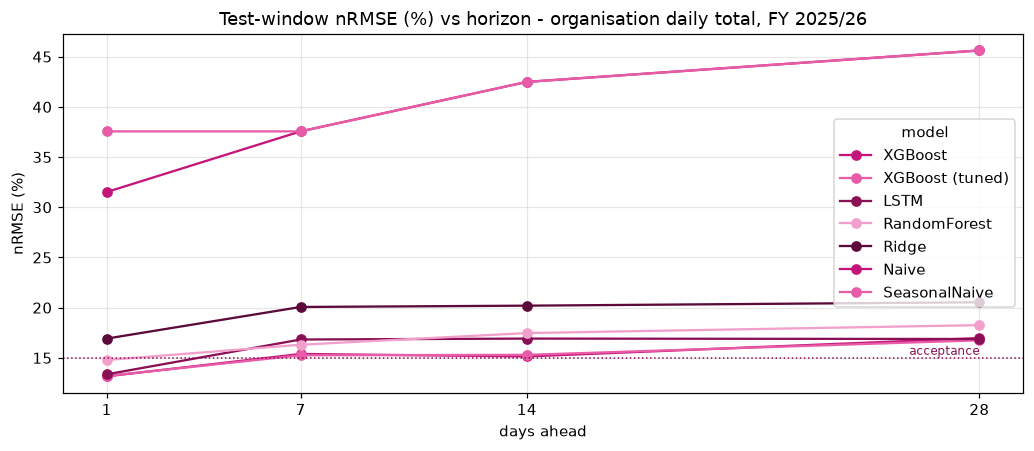

In [27]:
HORIZONS = (
    1,
    7,
    14,
    28,
)  # every model in make_models() is refitted per horizon (including LSTM)
rows = []
for h in HORIZONS:
    dts, x, y = build_features(gdf_total, horizon=h)
    xtr, xte, ytr, yte, _, _ = chrono_split(dts, x, y)
    rows += [
        {"horizon": h, "model": "Naive", **metrics(yte, naive_pred(xte, h))},
        {"horizon": h, "model": "SeasonalNaive", **metrics(yte, snaive_pred(xte, h))},
    ]
    for name, fn in {**make_models(), BEST_NAME: make_best}.items():
        m = fn()
        m.fit(xtr, ytr)
        rows.append({"horizon": h, "model": name, **metrics(yte, m.predict(xte))})

hor = pd.DataFrame(rows)
piv = (
    hor.pivot(index="model", columns="horizon", values="nRMSE_%").round(2).sort_values(HORIZONS[0])
)
display(piv)

ax = piv.T.plot(
    marker="o",
    title=f"Test-window nRMSE (%) vs horizon - organisation daily total, "
    f"{window_label(TEST_START, TEST_END)}",
)
ax.axhline(ACCEPT_NRMSE, color=PINKS[2], ls=":", lw=1)
ax.text(
    HORIZONS[-1], ACCEPT_NRMSE, " acceptance", fontsize=8, color=PINKS[2], va="bottom", ha="right"
)
ax.set_xlabel("days ahead")
ax.set_ylabel("nRMSE (%)")
ax.set_xticks(HORIZONS)
plt.tight_layout()

28. Splits the test window into weeks and forecasts each week from the evening before it starts (day k from the horizon-k model), for the tuned XGBoost with daily weather, the same model with 3-hourly weather, the LSTM and seasonal-naive.

In [28]:
# Weeks are seven-day blocks from TEST_START. A leftover shorter than MIN_OPEN_DAYS (such as the last day of a financial year) joins the final week; a longer one becomes a short final week.
# The horizon-k model only uses lags of at least k days, so nothing inside a week leaks into itsforecast.
#
# WEEKLY_REFIT = False: one model per horizon, trained once on the training window.
# WEEKLY_REFIT = True: models are retrained for each forecast day on all data before that week, as a weekly production run would. Much slower, so the LSTM is left out.
WEEKLY_REFIT = False
WEEKLY_INCLUDE_LSTM = True # ignored when WEEKLY_REFIT is True
WEEKLY_INCLUDE_3H = True # also run tuned XGBoost with 3-hourly weather
MIN_OPEN_DAYS = 4 # weeks with fewer open days are reported but not ranked

hold = pd.DataFrame({"date": pd.date_range(TEST_START, TEST_END, freq="D")})
hold["week"] = (hold["date"] - TEST_START).dt.days // 7 + 1
_n_full, _rem = divmod(len(hold), 7)
if _n_full and 0 < _rem < MIN_OPEN_DAYS:
    hold["week"] = hold["week"].clip(upper=_n_full)
hold["week_start"] = hold.groupby("week")["date"].transform("min")
hold["h"] = (hold["date"] - hold["week_start"]).dt.days + 1
MAX_H, N_WEEKS = int(hold["h"].max()), int(hold["week"].max())

WK_3H_NAME = f"{BEST_NAME}, 3-hourly weather"
wk_models = {BEST_NAME: (make_best, DEFAULT_WX)}
if WEEKLY_INCLUDE_3H:
    wk_models[WK_3H_NAME] = (make_best, WX_3H)
if WEEKLY_INCLUDE_LSTM and not WEEKLY_REFIT:
    wk_models["LSTM"] = (lambda: LSTMRegressor(), DEFAULT_WX)

feats = {h: build_features(gdf_total, horizon=h, weather_cols=WX_ALL) for h in range(1, MAX_H + 1)}

pred_rows = []
for h, (dts, x, y) in feats.items():
    target_days = hold.loc[hold["h"] == h, ["date", "week", "week_start"]]
    dts = pd.DatetimeIndex(dts)
    if not WEEKLY_REFIT:
        tr = in_window(dts, TRAIN_START, TRAIN_END)
        te = in_window(dts, TEST_START, TEST_END)
        te_dates = dts[te]
        by_model = {}
        for name, (fn, wx) in wk_models.items():
            xv = weather_variant(x, wx)
            m = fn()
            m.fit(xv[tr], y[tr])
            by_model[name] = pd.Series(m.predict(xv[te]), index=te_dates)
        snaive = pd.Series(snaive_pred(x[te], h), index=te_dates)
        actual = pd.Series(y[te].values, index=te_dates)
        for _, r in target_days.iterrows():
            if r["date"] in actual.index:
                pred_rows.append(
                    {
                        "date": r["date"],
                        "week": r["week"],
                        "h": h,
                        "actual": actual[r["date"]],
                        "SeasonalNaive": snaive[r["date"]],
                        **{n: s[r["date"]] for n, s in by_model.items()},
                    }
                )
    else:
        after_start = in_window(dts, TRAIN_START, None)
        for _, r in target_days.iterrows():
            t, ws = r["date"], r["week_start"]
            if t not in dts:
                continue  # closed day, or features incomplete
            tr = (dts < ws) & after_start  # everything known at the forecast origin
            win = (dts >= ws) & (dts <= t)  # predictors only; the last row is the target day
            row = {
                "date": t,
                "week": r["week"],
                "h": h,
                "actual": float(y[dts == t].iloc[0]),
                "SeasonalNaive": float(snaive_pred(x[dts == t], h)[0]),
            }
            for name, (fn, wx) in wk_models.items():
                xv = weather_variant(x, wx)
                m = fn()
                m.fit(xv[tr], y[tr])
                row[name] = float(m.predict(xv[win])[-1])
            pred_rows.append(row)

wk_pred = pd.DataFrame(pred_rows).sort_values("date").reset_index(drop=True)
MODEL_COLS = list(wk_models) + ["SeasonalNaive"]
print(
    f"Mode: {'weekly refit' if WEEKLY_REFIT else 'fixed training window'} | {len(wk_pred)} "
    "forecast days "
    f"across {wk_pred['week'].nunique()} of {N_WEEKS} weeks | horizons 1 to {MAX_H}"
)

Mode: fixed training window | 322 forecast days across 52 of 52 weeks | horizons 1 to 8


29. Scores each week, ranks the weeks from most to least predictable against seasonal-naive and the threshold, and compares daily with 3-hourly weather week by week.

In [29]:
def _week_scores(g, col):
    y, p = g["actual"].to_numpy(float), g[col].to_numpy(float)
    rmse = np.sqrt(np.mean((y - p) ** 2))
    return {
        "nRMSE_%": 100 * rmse / y.mean(),
        "MAPE_%": 100 * np.mean(np.abs((y - p) / y)),
        "week_total_err_%": 100 * (p.sum() - y.sum()) / y.sum(),
    }


wk_cal = hold.merge(gdf_total[["date", "oh_rain_1h_mm"]], on="date", how="left").assign(
    school_hol=school_holiday_flag(hold["date"]).values,
    bank_hol=bank_holiday_flag(hold["date"]).values,
)
wk_cal = wk_cal.groupby("week").agg(
    week_start=("date", "min"),
    week_end=("date", "max"),
    school_hol_days=("school_hol", "sum"),
    bank_hol_days=("bank_hol", "sum"),
    oh_rain_mm=("oh_rain_1h_mm", "sum"),
)

wrows = []
for w, g in wk_pred.groupby("week"):
    row = {"week": w, "open_days": len(g), "actual_total": g["actual"].sum()}
    for col in MODEL_COLS:
        sc = _week_scores(g, col)
        row.update({f"{col} {k}": v for k, v in sc.items()})
    wrows.append(row)
weekly = wk_cal.join(pd.DataFrame(wrows).set_index("week"), how="left")
weekly["open_days"] = weekly["open_days"].fillna(0).astype(int)
weekly["label"] = [
    f"wk {w:02d} ({a:%d %b}-{b:%d %b})"
    for w, a, b in zip(weekly.index, weekly["week_start"], weekly["week_end"])
]

PRIMARY_COL = f"{BEST_NAME} nRMSE_%"
COL_3H = f"{WK_3H_NAME} nRMSE_%"
HAS_3H = WK_3H_NAME in wk_models
ranked = weekly[weekly["open_days"] >= MIN_OPEN_DAYS].sort_values(PRIMARY_COL)
show = (
    [
        "label",
        "open_days",
        "school_hol_days",
        "bank_hol_days",
        "oh_rain_mm",
        "actual_total",
        PRIMARY_COL,
        f"{BEST_NAME} MAPE_%",
        f"{BEST_NAME} week_total_err_%",
    ]
    + ([COL_3H] if HAS_3H else [])
    + ["SeasonalNaive nRMSE_%"]
)

print(
    f"{len(weekly) - len(ranked)} week(s) with fewer than {MIN_OPEN_DAYS} open days left unranked"
)
print("\nMost predictable weeks:")
display(ranked[show].head(5).round(2))
print("Least predictable weeks:")
display(ranked[show].tail(5).iloc[::-1].round(2))

overall = {c: _week_scores(wk_pred, c)["nRMSE_%"] for c in MODEL_COLS}
print(
    "Whole-window nRMSE when every day is forecast from its week's origin: "
    + ", ".join(f"{k} {v:.2f}%" for k, v in overall.items())
)
_beats = (weekly[PRIMARY_COL] < weekly["SeasonalNaive nRMSE_%"]).sum()
_meets = (ranked[PRIMARY_COL] <= ACCEPT_NRMSE).sum()
print(
    f"{BEST_NAME} beats seasonal-naive in {_beats} of {weekly[PRIMARY_COL].notna().sum()} weeks, "
    f"and meets the {ACCEPT_NRMSE:.0f}% threshold in {_meets} of {len(ranked)} ranked weeks."
)

if HAS_3H:
    ranked = ranked.assign(
        delta_3h=ranked[COL_3H] - ranked[PRIMARY_COL]
    )  # negative = 3-hourly better
    WK_3H_WINS = int((ranked["delta_3h"] < 0).sum())
    print(
        f"\n3-hourly weather beats daily weather in {WK_3H_WINS} of {len(ranked)} ranked weeks "
        f"(median change {ranked['delta_3h'].median():+.2f} points of nRMSE, negative = 3-hourly "
        "better)."
    )
    print("Weeks where 3-hourly weather changed the error most:")
    display(
        ranked.reindex(ranked["delta_3h"].abs().sort_values(ascending=False).index)[
            ["label", "oh_rain_mm", "school_hol_days", PRIMARY_COL, COL_3H, "delta_3h"]
        ]
        .head(6)
        .round(2)
    )
    print(
        f"Correlation between a week's opening-hours rain and the 3-hourly change (Spearman): "
        f"{ranked['oh_rain_mm'].corr(ranked['delta_3h'], method='spearman'):.2f}"
    )

if "LSTM" in wk_models:
    # High agreement means the hard weeks are hard for any model.
    _rho = ranked[PRIMARY_COL].corr(ranked["LSTM nRMSE_%"], method="spearman")
    print(
        f"Rank agreement between {BEST_NAME} and LSTM on which weeks are hard (Spearman): "
        f"{_rho:.2f}"
    )

0 week(s) with fewer than 4 open days left unranked

Most predictable weeks:


,label,open_days,school_hol_days,bank_hol_days,oh_rain_mm,actual_total,XGBoost (tuned) nRMSE_%,XGBoost (tuned) MAPE_%,XGBoost (tuned) week_total_err_%,"XGBoost (tuned), 3-hourly weather nRMSE_%",SeasonalNaive nRMSE_%
week,,,,,,,,,,,
14,wk 14 (01 Jul-07 Jul),6,0,0,1.90,42163.0,4.81,4.40,4.09,7.01,9.52
39,wk 39 (23 Dec-29 Dec),4,7,2,0.00,23490.0,5.16,5.41,-2.01,9.89,39.78
27,wk 27 (30 Sep-06 Oct),6,0,0,17.41,35211.0,5.41,5.65,1.52,8.71,13.53
20,wk 20 (12 Aug-18 Aug),7,7,0,1.98,64608.0,5.58,5.12,1.02,7.01,22.12
35,wk 35 (25 Nov-01 Dec),6,0,0,13.31,25693.0,5.64,5.42,0.32,4.83,15.48


Least predictable weeks:


,label,open_days,school_hol_days,bank_hol_days,oh_rain_mm,actual_total,XGBoost (tuned) nRMSE_%,XGBoost (tuned) MAPE_%,XGBoost (tuned) week_total_err_%,"XGBoost (tuned), 3-hourly weather nRMSE_%",SeasonalNaive nRMSE_%
week,,,,,,,,,,,
3,wk 03 (15 Apr-21 Apr),7,7,2,10.26,70900.0,28.81,22.12,-23.91,27.94,34.27
10,wk 10 (03 Jun-09 Jun),6,0,0,11.98,46585.0,25.16,20.45,-21.79,24.52,32.09
37,wk 37 (09 Dec-15 Dec),6,0,0,14.68,20539.0,23.99,21.50,17.74,26.30,27.73
48,wk 48 (24 Feb-02 Mar),6,0,0,5.72,35585.0,23.14,26.62,15.23,23.79,118.20
32,wk 32 (04 Nov-10 Nov),6,0,0,12.98,27706.0,22.60,21.59,21.27,26.17,129.41


Whole-window nRMSE when every day is forecast from its week's origin: XGBoost (tuned) 15.31%, XGBoost (tuned), 3-hourly weather 15.37%, LSTM 15.37%, SeasonalNaive 37.63%
XGBoost (tuned) beats seasonal-naive in 48 of 52 weeks, and meets the 15% threshold in 36 of 52 ranked weeks.

3-hourly weather beats daily weather in 25 of 52 ranked weeks (median change +0.03 points of nRMSE, negative = 3-hourly better).
Weeks where 3-hourly weather changed the error most:


,label,oh_rain_mm,school_hol_days,XGBoost (tuned) nRMSE_%,"XGBoost (tuned), 3-hourly weather nRMSE_%",delta_3h
week,,,,,,
39,wk 39 (23 Dec-29 Dec),0.00,7,5.16,9.89,4.73
46,wk 46 (10 Feb-16 Feb),18.80,3,13.74,9.63,-4.10
32,wk 32 (04 Nov-10 Nov),12.98,0,22.60,26.17,3.58
27,wk 27 (30 Sep-06 Oct),17.41,0,5.41,8.71,3.30
41,wk 41 (06 Jan-12 Jan),18.63,0,17.28,14.30,-2.98
18,wk 18 (29 Jul-04 Aug),7.56,7,7.94,10.78,2.83


Correlation between a week's opening-hours rain and the 3-hourly change (Spearman): -0.09
Rank agreement between XGBoost (tuned) and LSTM on which weeks are hard (Spearman): 0.57


30. Plots error by week, highlighting the most and least predictable weeks, and shows those two weeks day by day.

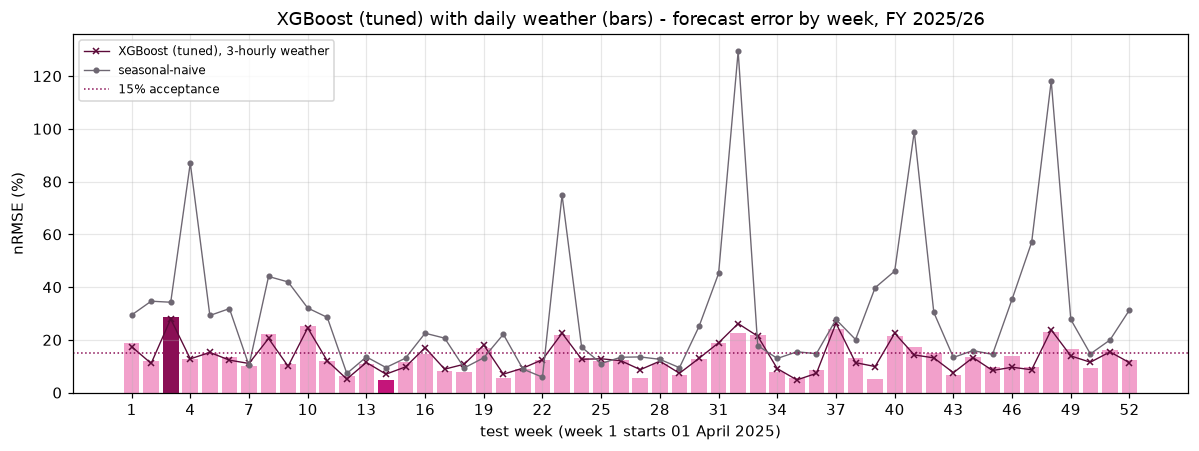

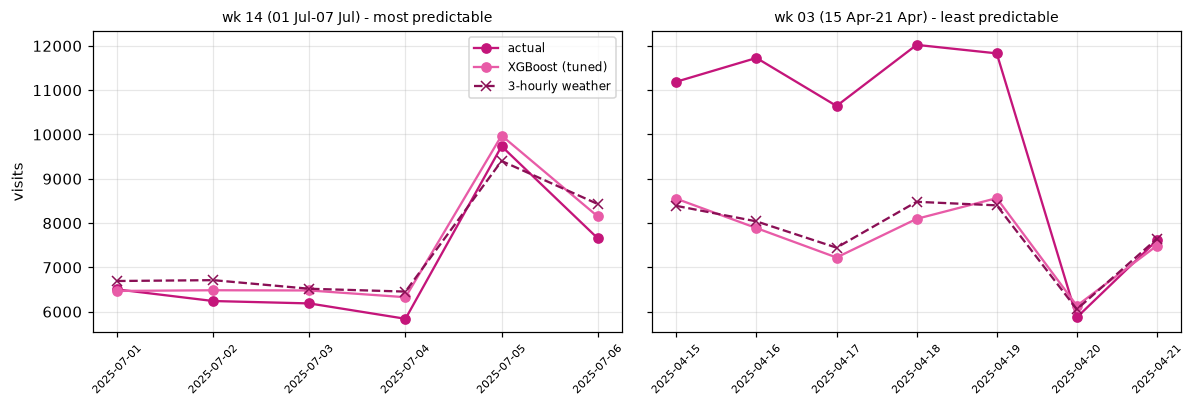

In [30]:
best_w, worst_w = (ranked.index[0], ranked.index[-1]) if len(ranked) else (None, None)
colours = [
    PINKS[2] if w == worst_w else PINKS[0] if w == best_w else PINKS[3] for w in weekly.index
]
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.bar(weekly.index, weekly[PRIMARY_COL], color=colours)
if HAS_3H:
    ax.plot(
        weekly.index,
        weekly[COL_3H],
        color=PINKS[4],
        lw=0.9,
        marker="x",
        ms=4,
        label=f"{BEST_NAME}, 3-hourly weather",
    )
ax.plot(
    weekly.index,
    weekly["SeasonalNaive nRMSE_%"],
    color="#6E6772",
    lw=0.9,
    marker=".",
    label="seasonal-naive",
)
ax.axhline(ACCEPT_NRMSE, color=PINKS[2], ls=":", lw=1, label=f"{ACCEPT_NRMSE:.0f}% acceptance")
ax.set_xlabel(f"test week (week 1 starts {TEST_START:%d %B %Y})")
ax.set_ylabel("nRMSE (%)")
ax.set_title(
    f"{BEST_NAME} with daily weather (bars) - forecast error by week, "
    f"{window_label(TEST_START, TEST_END)}"
)
ax.set_xticks(range(1, N_WEEKS + 1, max(1, N_WEEKS // 17)))
ax.legend(fontsize=8)
plt.tight_layout()

if best_w is not None:
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
    for ax, w, tag in (
        (axes[0], best_w, "most predictable"),
        (axes[1], worst_w, "least predictable"),
    ):
        g = wk_pred[wk_pred["week"] == w]
        ax.plot(g["date"], g["actual"], marker="o", label="actual")
        ax.plot(g["date"], g[BEST_NAME], marker="o", label=BEST_NAME)
        if HAS_3H:
            ax.plot(g["date"], g[WK_3H_NAME], marker="x", ls="--", label="3-hourly weather")
        ax.set_title(f"{weekly.loc[w, 'label']} - {tag}", fontsize=9)
        ax.tick_params(axis="x", labelrotation=45, labelsize=7)
    axes[0].set_ylabel("visits")
    axes[0].legend(fontsize=8)
    plt.tight_layout()

31. Refits the same tuned configuration on the organisation series and on each venue, with no venue-specific tuning, to test how well it generalises. As in CA2, venues with too little test-window data (MM and ISM, closed for redevelopment) are listed without a score.

horizon,1,7
series,,
ALL (median venue),21.00,22.15
ALL (total),13.20,15.26
ISM,NaN,NaN
LLAG,31.43,32.84
MM,NaN,NaN
MoL,19.72,21.18
SH,61.41,61.51
WAG,16.72,19.20
WM,21.85,24.87


,series,horizon,test_from,train_days,test_days,nRMSE_%,snaive_nRMSE_%,beats_snaive,meets_threshold,note
0,ALL (total),1,2025-04-01,3868,322,13.20,37.56,True,True,
1,ALL (total),7,2025-04-01,3868,322,15.26,37.56,True,False,
2,ALL (median venue),1,2025-04-01,3866,322,21.00,35.45,True,False,
3,ALL (median venue),7,2025-04-01,3866,322,22.15,35.45,True,False,
4,WM,1,2025-04-01,5420,322,21.85,55.52,True,False,
5,WM,7,2025-04-01,5420,322,24.87,55.52,True,False,
6,WAG,1,2025-04-01,5400,322,16.72,34.53,True,False,
7,WAG,7,2025-04-01,5400,322,19.20,34.53,True,False,
8,MM,1,None,0,0,NaN,NaN,NaN,NaN,closed - no test-window data
9,MM,7,None,0,0,NaN,NaN,NaN,NaN,closed - no test-window data


XGBoost (tuned) beats seasonal-naive at 5 of 5 scored venues (h=1) and meets the 15% threshold at 0. Not scored: ISM, MM.


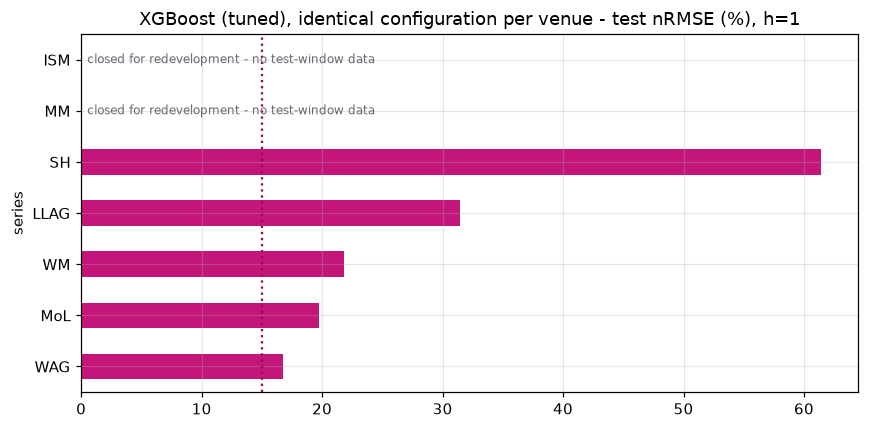

In [31]:
gen_rows = []
for label, frame in {"ALL (total)": gdf_total, "ALL (median venue)": gdf_median}.items():
    for h in (1, 7):
        dts, x, y = build_features(frame, horizon=h)
        xtr, xte, ytr, yte, _, _ = chrono_split(dts, x, y)
        m = make_best()
        m.fit(xtr, ytr)
        gen_rows.append(
            {
                "series": label,
                "horizon": h,
                "test_from": TEST_START.date(),
                "train_days": len(ytr),
                "test_days": len(yte),
                **metrics(yte, m.predict(xte)),
                "snaive_nRMSE_%": metrics(yte, snaive_pred(xte, h))["nRMSE_%"],
                "note": "",
            }
        )

MIN_TEST_DAYS = 90  # open days a venue needs in the test window to be scored
for code in ACTIVE:
    cols = ["date", "visits"] + [c for c in WX_ALL if c in daily[code].columns]
    frame = daily[code][cols]
    _open = pd.to_numeric(frame["visits"], errors="coerce") > 0
    _in_test = int((_open & in_window(frame["date"], TEST_START, TEST_END)).sum())
    if _in_test < MIN_TEST_DAYS:
        # As in CA2: nothing to score in the test window, so the row is left empty.
        for h in (1, 7):
            gen_rows.append(
                {
                    "series": code,
                    "horizon": h,
                    "test_from": None,
                    "train_days": 0,
                    "test_days": _in_test,
                    "note": "closed - no test-window data",
                }
            )
        continue
    for h in (1, 7):
        dts, x, y = build_features(frame, horizon=h)
        xtr, xte, ytr, yte, _, _ = chrono_split(dts, x, y)
        m = make_best()
        m.fit(xtr, ytr)
        gen_rows.append(
            {
                "series": code,
                "horizon": h,
                "test_from": TEST_START.date(),
                "train_days": len(ytr),
                "test_days": len(yte),
                **metrics(yte, m.predict(xte)),
                "snaive_nRMSE_%": metrics(yte, snaive_pred(xte, h))["nRMSE_%"],
                "note": "",
            }
        )

ven = pd.DataFrame(gen_rows)
_scored = ven["nRMSE_%"].notna()
ven["beats_snaive"] = (ven["nRMSE_%"] < ven["snaive_nRMSE_%"]).where(_scored)
ven["meets_threshold"] = (ven["nRMSE_%"] <= ACCEPT_NRMSE).where(_scored)
display(ven.pivot(index="series", columns="horizon", values="nRMSE_%").round(2))
display(
    ven[
        [
            "series",
            "horizon",
            "test_from",
            "train_days",
            "test_days",
            "nRMSE_%",
            "snaive_nRMSE_%",
            "beats_snaive",
            "meets_threshold",
            "note",
        ]
    ].round(2)
)
_v = ven[~ven["series"].str.startswith("ALL")]
_n_open = _v.loc[_v["nRMSE_%"].notna(), "series"].nunique()
print(
    f"{BEST_NAME} beats seasonal-naive at "
    f"{int(_v.query('horizon == 1')['beats_snaive'].eq(True).sum())} of "
    f"{_n_open} scored venues (h=1) and meets the {ACCEPT_NRMSE:.0f}% threshold at "
    f"{int(_v.query('horizon == 1')['meets_threshold'].eq(True).sum())}. Not scored: "
    f"{', '.join(sorted(_v.loc[_v['nRMSE_%'].isna(), 'series'].unique())) or 'none'}."
)

# Scored venues by error, then the unscored venues as empty rows, as in CA2.
vh1 = ven[(ven["horizon"] == 1) & (~ven["series"].str.startswith("ALL"))].set_index("series")[
    "nRMSE_%"
]
vh1 = pd.concat([vh1.dropna().sort_values(), vh1[vh1.isna()]])
ax = vh1.plot.barh(
    title=f"{BEST_NAME}, identical configuration per venue - test nRMSE (%), h=1", figsize=(8, 4)
)
for _i, (_s, _val) in enumerate(vh1.items()):
    if pd.isna(_val):
        ax.text(
            0.5,
            _i,
            "closed for redevelopment - no test-window data",
            va="center",
            fontsize=8,
            color="#6E6772",
        )
ax.axvline(ACCEPT_NRMSE, color=PINKS[2], ls=":")
plt.tight_layout()

32. Monthly design for the primary venue (monthly lags and a 12-month rolling mean) against seasonal-naive and SARIMA, on complete months inside the test window. Disruption periods are neither flagged nor dropped here; closed days count as zero visits.

In [32]:
mfrm = daily[PRIMARY_VENUE][["date", "visits"]].set_index("date").asfreq("D")
_mv = pd.to_numeric(mfrm["visits"], errors="coerce")
if CLOSED_IS_ZERO:
    _mv = within_span_zero(_mv)  # a day with no row inside the span is also a closure
monthly = _mv.resample("MS").sum(min_count=1).to_frame("visits")
monthly = monthly.join(
    gdf_total.set_index("date")[["oh_temp_c", "oh_rain_1h_mm", "temp_c", "rain_1h_mm"]]
    .resample("MS")
    .mean()
)
# Complete months only: a month still in progress would look like a collapse.
monthly = monthly[monthly.index + pd.offsets.MonthEnd(0) <= DATA_END]


def monthly_features(mf, horizon=1):
    df = mf.copy()
    df["month"], df["year"] = df.index.month, df.index.year
    for lag in (1, 2, 3, 12, 24):
        if lag >= horizon:
            df[f"lag_{lag}"] = df["visits"].shift(lag)
    df["roll_12"] = df["visits"].shift(horizon).rolling(12).mean()
    data = df.dropna()
    x = pd.get_dummies(data.drop(columns=["visits"]), columns=["month"]).astype(float)
    return data.index, x, data["visits"].astype(float)


mi_, mx, my = monthly_features(monthly, horizon=1)
_mend = mi_ + pd.offsets.MonthEnd(0)
mtr = in_window(mi_, TRAIN_START, None) & (_mend <= TRAIN_END)
mte = (mi_ >= TEST_START) & (_mend <= TEST_END)

m_res = {}
if mte.sum() == 0 or mtr.sum() == 0:
    print("No complete month falls inside the test window, so the monthly comparison is skipped.")
else:
    mxtr, mxte, mytr, myte = mx[mtr], mx[mte], my[mtr], my[mte]
    m_res["SeasonalNaive (t-12)"] = metrics(myte, mxte["lag_12"].values)
    # SARIMA is fitted on the training months, then stepped forward without refitting to the end of
    # the test window. Disrupted months stay in, with closures counted as zero.
    post_m = my[(mi_ > mytr.index.max()) & (mi_ <= myte.index.max())]
    sm = SARIMAX(
        mytr.asfreq("MS"),
        order=(0, 1, 1),
        seasonal_order=(0, 1, 1, 12),
        enforce_stationarity=False,
        enforce_invertibility=False,
    ).fit(disp=False)
    sp = (
        sm.append(post_m.asfreq("MS"), refit=False)
        .get_prediction(start=post_m.index[0], end=post_m.index[-1])
        .predicted_mean
    )
    m_res["SARIMA(0,1,1)(0,1,1)12"] = metrics(myte, sp.loc[myte.index].values)
    mm_ = make_best()
    mm_.fit(mxtr, mytr)
    m_res[BEST_NAME] = metrics(myte, mm_.predict(mxte))
    print(
        f"{len(mytr)} training months, {len(myte)} test months "
        f"({myte.index.min():%b %Y} to {myte.index.max():%b %Y})"
    )
    display(pd.DataFrame(m_res).T.round(2))

141 training months, 12 test months (Apr 2025 to Mar 2026)


,RMSE,nRMSE_%,MAE,MAPE_%,R2
SeasonalNaive (t-12),11218.61,13.98,8154.83,9.12,0.77
"SARIMA(0,1,1)(0,1,1)12",9199.61,11.46,6666.84,8.49,0.85
XGBoost (tuned),7028.36,8.76,5515.53,6.91,0.91


33. Hourly design for opening hours, with same-hour lags at 1 and 7 days, comparing no weather, hourly weather and 3-hourly block weather against same-hour-last-week. Hourly weather is converted from UTC to local time before joining. Disruption periods are handled as in build_features().

In [33]:
# visits_hourly is in local time and weather_hourly.dt is UTC, so the weather is converted to
# Europe/London first; otherwise each hour's visits would meet the next hour's weather during
# British Summer Time. weather_3hourly is already in local time.
HWX = ["temp_c", "feels_like_c", "rain_1h_mm", "snow_1h_mm", "wind_speed_ms", "clouds_pct"]
HWX_BLK = [f"blk_{c}" for c in HWX]
_area = VENUE_AREA[PRIMARY_VENUE]

hv = qdf(f"""SELECT `datetime` AS dt, visits FROM visits_hourly
            WHERE venue_id = '{PRIMARY_VENUE}' AND `datetime` <= '{DATA_END.date()} 23:59:59'
            ORDER BY dt""")
_h_from = (hv["dt"].min() - pd.Timedelta(days=1)).date()
_h_to = (DATA_END + pd.Timedelta(days=2)).date()
whr = qdf(f"""SELECT dt, {', '.join(HWX)} FROM weather_hourly
             WHERE area = '{_area}' AND dt >= '{_h_from}' AND dt < '{_h_to}' ORDER BY dt""")
whr["dt"] = whr["dt"].dt.tz_localize("UTC").dt.tz_convert("Europe/London").dt.tz_localize(None)
whr = whr.drop_duplicates("dt")  # the hour that repeats when the clocks go back
blk = qdf(f"""SELECT start_dt, {', '.join(HWX)} FROM weather_3hourly
             WHERE area = '{_area}' AND start_dt >= '{_h_from}' AND start_dt < '{_h_to}'""")
blk = blk.rename(columns={"start_dt": "block_dt", **dict(zip(HWX, HWX_BLK))})

hdf = hv.merge(whr, on="dt", how="left")
hdf["block_dt"] = hdf["dt"].dt.floor("3h")  # the local 3-hour block each hour falls in
hdf = hdf.merge(blk, on="block_dt", how="left").drop(columns="block_dt")
hdf["visits"] = pd.to_numeric(hdf["visits"], errors="coerce")
hdf = hdf[hdf["dt"].dt.hour.between(10, 16) & (hdf["visits"] > 0)].copy()

for nm, days_ in (("lag_1d", 1), ("lag_7d", 7)):
    lag = hdf[["dt", "visits"]].copy()
    lag["dt"] = lag["dt"] + pd.Timedelta(days=days_)
    hdf = hdf.merge(lag.rename(columns={"visits": nm}), on="dt", how="left")

hdf["hour"], hdf["dow"] = hdf["dt"].dt.hour, hdf["dt"].dt.dayofweek
hdf["school_hol"] = school_holiday_flag(hdf["dt"].dt.normalize()).values
hdf["school_hol_share"] = school_holiday_share(hdf["dt"].dt.normalize()).values
hdf["bank_hol"] = bank_holiday_flag(hdf["dt"].dt.normalize()).values
if not DROP_DISRUPTED_DAYS:
    for _name, (_a, _b) in DISRUPTIONS.items():
        hdf[_name] = hdf["dt"].dt.normalize().between(_a, _b).astype(int)
hdata = hdf.dropna()  # hourly and block weather both present, so identical rows
hx = pd.get_dummies(hdata.drop(columns=["dt", "visits"]), columns=["hour", "dow"]).astype(float)
hy, hd = hdata["visits"].astype(float), hdata["dt"]
htr, hte = in_window(hd, TRAIN_START, TRAIN_END), in_window(hd, TEST_START, TEST_END)
if DROP_DISRUPTED_DAYS:
    htr &= ~disrupted(hd)

H_VARIANTS = {"no weather": [], "hourly weather": HWX, "3-hourly block weather": HWX_BLK}
h_res = {"SeasonalNaive (same hour, t-7d)": metrics(hy[hte], hdata.loc[hte, "lag_7d"].values)}
for name, keep in H_VARIANTS.items():
    cols = [c for c in hx.columns if c not in HWX + HWX_BLK or c in keep]
    hm = make_best()
    hm.fit(hx.loc[htr, cols], hy[htr])
    h_res[f"{BEST_NAME}, {name}"] = metrics(hy[hte], hm.predict(hx.loc[hte, cols]))
print(
    f"{PRIMARY_VENUE} opening hours: {int(htr.sum())} training hours, {int(hte.sum())} test hours"
)
display(pd.DataFrame(h_res).T.round(2))

MoL opening hours: 3116 training hours, 1834 test hours


,RMSE,nRMSE_%,MAE,MAPE_%,R2
"SeasonalNaive (same hour, t-7d)",178.71,39.99,129.65,35.24,0.33
"XGBoost (tuned), no weather",118.45,26.50,87.33,21.94,0.71
"XGBoost (tuned), hourly weather",118.02,26.41,86.48,21.83,0.71
"XGBoost (tuned), 3-hourly block weather",119.00,26.63,87.13,22.07,0.70


34. forecast_next_days() fits one model per horizon, adds 80% intervals from validation residual quantiles, and gives a seven-day forecast for the primary venue (which can be added to a central database with PowerBI connection in production).

Forecast for the seven days after the loaded data: 2026-04-01 to 2026-04-07


,date,h,yhat,lo80,hi80
0,2026-04-01,1,3989.0,3531.0,4652.0
1,2026-04-02,2,3823.0,3358.0,4516.0
2,2026-04-03,3,3755.0,3319.0,4535.0
3,2026-04-04,4,3384.0,2947.0,4137.0
4,2026-04-05,5,2956.0,2536.0,3748.0
5,2026-04-06,6,3614.0,3160.0,4405.0
6,2026-04-07,7,3538.0,3103.0,4344.0


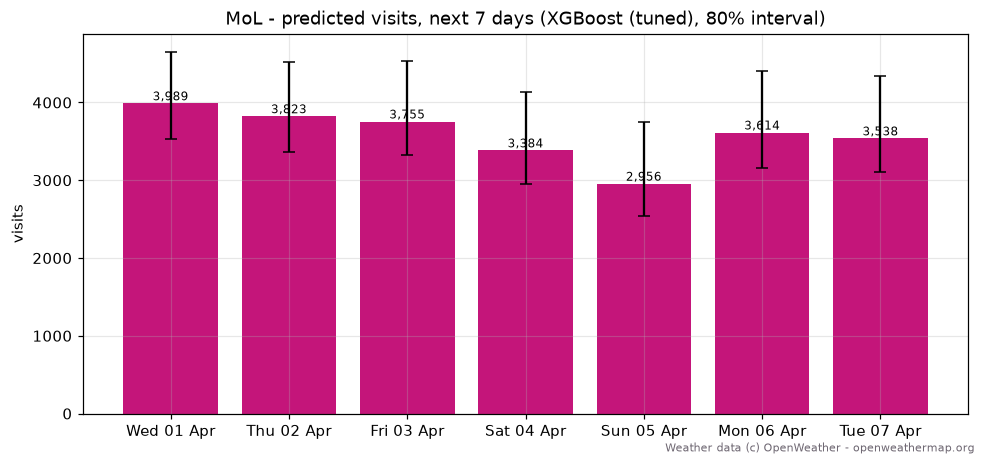

In [34]:
def forecast_next_days(frame, wx_future, model_maker, days=7):
    """frame: history with date, visits and weather. wx_future: weather for the next `days` dates,
    which in production would come from a weather forecast feed."""
    need = ["date", "visits"] + [c for c in DEFAULT_WX if c in frame.columns]
    fut = wx_future.copy()
    fut["visits"] = np.nan
    fut = fut[[c for c in need if c in fut.columns]]
    allf = pd.concat([frame[need], fut], ignore_index=True)
    out = []
    for h in range(1, days + 1):
        dts, xk, yk, fdt, xf = build_features(allf, horizon=h, return_future=True)
        n, k = len(xk), int(len(xk) * 0.85)
        mv = model_maker()
        mv.fit(xk.iloc[:k], yk.iloc[:k])
        resid = yk.iloc[k:].values - mv.predict(xk.iloc[k:])
        lo_q, hi_q = np.quantile(resid, [0.10, 0.90])
        m = model_maker()
        m.fit(xk, yk)
        tgt = wx_future["date"].iloc[h - 1]
        sel = xf[(fdt == tgt).values]
        if len(sel) == 0:
            out.append({"date": tgt, "h": h, "yhat": np.nan, "lo80": np.nan, "hi80": np.nan})
            continue
        yhat = float(m.predict(sel)[0])
        out.append(
            {"date": tgt, "h": h, "yhat": yhat, "lo80": max(0.0, yhat + lo_q), "hi80": yhat + hi_q}
        )
    return pd.DataFrame(out)


hcols = ["date", "visits"] + [c for c in DEFAULT_WX if c in daily[PRIMARY_VENUE].columns]
hist = daily[PRIMARY_VENUE][hcols]

# Stand-in weather forecast: the same week last year, until a forecast feed is connected.
last = hist["date"].max()
fdates = pd.date_range(last + pd.Timedelta(days=1), periods=7)
wx_fc = hist[hist["date"].isin(fdates - pd.Timedelta(days=364))].copy()
wx_fc["date"] = wx_fc["date"] + pd.Timedelta(days=364)
wx_fc = wx_fc.drop(columns=["visits"]).reset_index(drop=True)

fc7 = forecast_next_days(hist, wx_fc, make_best, days=7)
print(
    f"Forecast for the seven days after the loaded data: {fdates[0].date()} to {fdates[-1].date()}"
)
display(fc7.round({"yhat": 0, "lo80": 0, "hi80": 0}))

fig, ax = plt.subplots(figsize=(9, 4.2))
ok = fc7.dropna()
err = np.vstack([ok["yhat"] - ok["lo80"], ok["hi80"] - ok["yhat"]])
ax.bar(ok["date"].dt.strftime("%a %d %b"), ok["yhat"], yerr=err, capsize=4, color=PINKS[0])
for i, v in enumerate(ok["yhat"]):
    ax.text(i, v, f"{v:,.0f}", ha="center", va="bottom", fontsize=8)
ax.set_title(f"{PRIMARY_VENUE} - predicted visits, next 7 days ({BEST_NAME}, 80% interval)")
ax.set_ylabel("visits")
plt.figtext(
    0.99,
    0.01,
    "Weather data (c) OpenWeather - openweathermap.org",
    ha="right",
    fontsize=7,
    color="#6E6772",
)
plt.tight_layout()

35. Headline figures from every section in one table, taken from the variables above rather than typed in, for checking the write-up against the latest run.

In [35]:
# nRMSE is RMSE divided by mean actual visits; 100 - nRMSE is not an accuracy score.
# Every model scored at h = 1 on the organisation total: sections 14-19, plus section 27, where the XGBoost family is first scored on the test window.
_h1 = pd.concat(
    [pd.DataFrame(results_h1).T["nRMSE_%"], hor[hor["horizon"] == 1].set_index("model")["nRMSE_%"]]
).to_frame("nRMSE_%")
_best_h1 = _h1["nRMSE_%"].idxmin()
_ab = abl.set_index(["series", "horizon", "variant"])["test_delta"]
_h0 = ABL_HORIZONS[0]
_wx = abl[abl["variant"].isin(WX_VARIANTS)]
_m = pd.DataFrame(m_res).T
_ven1 = ven.query("series == @PRIMARY_VENUE and horizon == 1")["nRMSE_%"]

summary = [
    ("Training window", window_label(TRAIN_START, TRAIN_END)),
    ("Test window", f"{window_label(TEST_START, TEST_END)}, {N_WEEKS} weeks"),
    (
        "Disruption periods",
        "; ".join(
            f"{n.replace('_', ' ')} {a:%d %b %Y} to {b:%d %b %Y}"
            for n, (a, b) in DISRUPTIONS.items()
        )
        + (" (dropped from training)" if DROP_DISRUPTED_DAYS else " (0/1 features)"),
    ),
    (
        "Organisation total, h=1: best model on the test window",
        f"{_best_h1} {_h1.loc[_best_h1, 'nRMSE_%']:.2f}%",
    ),
    (
        f"Organisation total, tuned XGBoost at h = {' / '.join(map(str, HORIZONS))}",
        " / ".join(f"{piv.loc[BEST_NAME, h]:.2f}%" for h in HORIZONS),
    ),
    (
        "LSTM across seeds (mean +/- std)",
        f"{seed_summary.loc['LSTM', 'mean']:.2f} +/- {seed_summary.loc['LSTM', 'std']:.2f}%",
    ),
    (
        "Tuned XGBoost across seeds (mean +/- std)",
        f"{seed_summary.loc[BEST_NAME, 'mean']:.2f} +/- {seed_summary.loc[BEST_NAME, 'std']:.2f}%",
    ),
    *[
        (
            f"Organisation h={_h0}, {v} vs daily-weather base (test-window delta)",
            f"{_ab.loc[('ALL (total)', _h0, v)]:+.2f} points",
        )
        for v in ABL_VARIANTS
        if v != ABL_BASE
    ],
    (
        "Largest absolute weather-variant delta, any series or horizon",
        f"{_wx['test_delta'].abs().max():.2f} points",
    ),
    (
        "Positive permutation importance: daily / 3-hourly weather",
        f"{WX_SHARE['daily weather']:.1f}% / {WX_SHARE['3-hourly weather']:.1f}%",
    ),
    (
        "3-hourly weather columns confirmed / tentative by Boruta",
        f"{sum(c in WX_3H for c in confirmed)} / {sum(c in WX_3H for c in tentative)} of "
        f"{len(WX_3H)}",
    ),
    (
        "Daily weather columns confirmed / tentative by Boruta",
        f"{sum(c in DEFAULT_WX for c in confirmed)} / {sum(c in DEFAULT_WX for c in tentative)} "
        f"of {len(DEFAULT_WX)}",
    ),
]
if best_w is not None:
    summary += [
        (
            "Most predictable week",
            f"{weekly.loc[best_w, 'label']}: {weekly.loc[best_w, PRIMARY_COL]:.2f}%",
        ),
        (
            "Least predictable week",
            f"{weekly.loc[worst_w, 'label']}: {weekly.loc[worst_w, PRIMARY_COL]:.2f}%",
        ),
    ]
if HAS_3H:
    summary.append(
        (
            "Weeks where 3-hourly weather beats daily weather",
            f"{WK_3H_WINS} of {len(ranked)} ranked weeks",
        )
    )
if len(_ven1):
    summary.append((f"{PRIMARY_VENUE} h=1 (generalisation test)", f"{_ven1.iloc[0]:.2f}%"))
summary.append(
    (
        f"{PRIMARY_VENUE} month ahead: best model",
        (
            f"{_m['nRMSE_%'].idxmin()} {_m['nRMSE_%'].min():.2f}%"
            if len(_m)
            else "no complete test month"
        ),
    )
)
summary.append(
    (
        f"{PRIMARY_VENUE} hourly: tuned XGBoost with no / hourly / 3-hourly weather vs "
        "seasonal-naive",
        " / ".join(f"{h_res[f'{BEST_NAME}, {n}']['nRMSE_%']:.2f}%" for n in H_VARIANTS)
        + f" vs {h_res['SeasonalNaive (same hour, t-7d)']['nRMSE_%']:.2f}%",
    )
)
summary.append(
    (
        "Local-authority days from term_dates: train / test window",
        f"{TD_SHARE['train']:.1f}% / {TD_SHARE['test']:.1f}%",
    )
)
pd.DataFrame(summary, columns=["figure", "value (nRMSE unless stated)"]).style.hide(axis="index")

figure,value (nRMSE unless stated)
Training window,start of data to 31 Mar 2025
Test window,"FY 2025/26, 52 weeks"
Disruption periods,covid 18 Mar 2020 to 17 May 2021; strike action 17 Feb 2024 to 04 Jun 2024 (dropped from training)
"Organisation total, h=1: best model on the test window",XGBoost 13.16%
"Organisation total, tuned XGBoost at h = 1 / 7 / 14 / 28",13.20% / 15.26% / 15.30% / 16.75%
LSTM across seeds (mean +/- std),13.42 +/- 0.21%
Tuned XGBoost across seeds (mean +/- std),13.26 +/- 0.12%
"Organisation h=1, no weather vs daily-weather base (test-window delta)",+0.64 points
"Organisation h=1, 3-hourly instead of daily vs daily-weather base (test-window delta)",+0.37 points
"Organisation h=1, daily + 3-hourly vs daily-weather base (test-window delta)",+0.44 points


36. comparison of best ranked feature vs weather hypothesis.

In [36]:
imp = pd.Series(pi.importances_mean, index=x1a_tr.columns).clip(lower=0)
wx = imp[[c for c in imp.index if feature_group(c) in ("daily weather", "3-hourly weather")]].sum()
print(f"Saturday: {imp['dow_5']:.4f} | all weather combined: {wx:.4f} | "
      f"ratio: {imp['dow_5'] / wx:.1f}x")

Saturday: 0.1468 | all weather combined: 0.0079 | ratio: 18.5x
